# Research-ready PG-MMIL pipeline for retail shoplifting detection

**Project:** Cross-Domain Pose-Guided Multimodal Multiple-Instance Learning (PG-MMIL) for weakly supervised retail shoplifting detection.

This notebook extends the supplied implementation. It keeps the four source domains (UCF-Crime retail subset, DCSASS, MNNIT-S3, and Shop-Dataset), the 32-snippet feature representation, YOLO pose features, CLIP ViT-B/32 visual features, and four prompt-similarity features.

## Research protocol changes

- A **group-aware train / validation / test split** is created. Exact duplicate feature bags are grouped and cannot cross partitions.
- Checkpoint selection and decision-threshold selection use **validation data only**. The independent test set is evaluated after model selection.
- The cross-domain experiment is a true **leave-one-domain-out (LODO)** evaluation: the target domain is excluded from both training and validation.
- Metrics include ROC-AUC, Average Precision (reported as PR-AUC/AP), precision, recall, F1, specificity, balanced accuracy, MCC, false-alarm rate, recall at low FPR, and Brier score.
- Three default random seeds, cluster-bootstrap confidence intervals, optional component ablations, and inference profiling are included.
- Interpolated snippet scores are presented only as qualitative curves. Frame-level localization metrics are skipped unless genuine temporal annotations are supplied.

**Important interpretation:** The Sultani-, RTFM-, and VadCLIP-named implementations in this notebook are *inspired benchmark configurations*, not verified exact reproductions of the original papers. Do not claim exact reproduction or state-of-the-art superiority from these custom implementations alone. Cite and compare with original methods separately in the paper.

**Run order:** Execute cells from top to bottom. Dataset download and feature extraction require network access and substantial storage/GPU time. Existing original results are intentionally cleared from this revised notebook; rerun experiments to produce new valid results.

## Phase 0 — research protocol, reproducibility, and security

Before running the experiments, read and edit the configuration cells. Keep the test partition untouched until final reporting. Record package versions, hardware, seeds, dataset manifest, feature-extraction signature, and split manifest with every result.

### Critical credential hygiene

The supplied notebook contained a hard-coded GitHub personal access token. It has been removed from this notebook. **Revoke that exposed token in GitHub immediately** and create a replacement only if you need one. Never paste secrets into notebook source, cell output, Git remotes, or exported ZIP files. The backup section below deliberately does not implement token-based Git pushes.

In [1]:
!pip install -q "huggingface_hub[hf_xet,hf_transfer]" ultralytics open_clip_torch pandas opencv-python tqdm scikit-learn scipy matplotlib seaborn ipywidgets

import os
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

import re, json, cv2, warnings, random, hashlib, platform, sys, subprocess, copy, time
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
from huggingface_hub import HfFileSystem, hf_hub_download
import ipywidgets as widgets
from IPython.display import display

# Keep warnings visible: deprecations and data issues should not be hidden.

# --- 1. Inputs & Environment Configuration ---
HF_DATASET_ID = "NaveenKumarGottipalli/Shoplifting_DataCollection"
LOCAL_BASE_DIR = Path("/content/local_shoplifting_data")
LOCAL_BASE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = LOCAL_BASE_DIR / "paper_figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Interactive Data Source Selection Widget
print("==================================================================")
print(" 🚀 SHOPLIFTING DETECTION RESEARCH PIPELINE: DATA SOURCE SETUP")
print("==================================================================")

source_widget = widgets.RadioButtons(
    options=[
        'Hugging Face Hub (NaveenKumarGottipalli/Shoplifting_DataCollection)',
        'Google Drive (/content/drive/MyDrive/Dataset)'
    ],
    value='Hugging Face Hub (NaveenKumarGottipalli/Shoplifting_DataCollection)',
    description='Select Source:',
    disabled=False,
    style={'description_width': 'initial'},
    layout={'width': 'max-content'}
)

display(source_widget)
print("👉 Select your data source above, then run the next cell.")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


 🚀 SHOPLIFTING DETECTION RESEARCH PIPELINE: DATA SOURCE SETUP


RadioButtons(description='Select Source:', layout=Layout(width='max-content'), options=('Hugging Face Hub (Nav…

👉 Select your data source above, then run the next cell.


In [2]:
# Save an environment snapshot for reproducibility. Run after setup cell.
import importlib.metadata as metadata
import torch

ENV_SNAPSHOT = {
    "python": sys.version,
    "platform": platform.platform(),
    "device": device if "device" in globals() else ("cuda" if torch.cuda.is_available() else "cpu"),
    "torch": torch.__version__ if "torch" in globals() else "not imported",
    "cuda": torch.version.cuda if "torch" in globals() and torch.cuda.is_available() else None,
}
for package in ["numpy", "pandas", "scikit-learn", "opencv-python", "ultralytics", "open-clip-torch", "huggingface-hub", "matplotlib", "seaborn", "scipy"]:
    try:
        ENV_SNAPSHOT[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        ENV_SNAPSHOT[package] = "not installed"
(LOCAL_BASE_DIR / "environment_snapshot.json").write_text(json.dumps(ENV_SNAPSHOT, indent=2), encoding="utf-8")
print(json.dumps(ENV_SNAPSHOT, indent=2))

{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "device": "cuda",
  "torch": "2.11.0+cu130",
  "cuda": "13.0",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "opencv-python": "5.0.0.93",
  "ultralytics": "8.4.197",
  "open-clip-torch": "3.3.0",
  "huggingface-hub": "1.33.0",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2",
  "scipy": "1.16.3"
}


## Phase 1 — dataset discovery and manifest curation

The following cell preserves the supplied dataset discovery and labelling rules. Inspect `unified_training_manifest.csv` before training. The normal-video retail filtering rule is heuristic; document it as part of dataset construction and manually audit a sample of accepted and rejected records.

In [4]:
# --- 2. Manifest Creation & Dual-Source Import (Google Drive or Hugging Face) ---
import google.colab
from google.colab import drive

chosen_source = source_widget.value
USE_GOOGLE_DRIVE = "Google Drive" in chosen_source
DRIVE_BASE_DIR = Path("/content/drive/MyDrive/Dataset")

VID_EXT = {".mp4", ".avi", ".mkv", ".webm", ".mov"}

RETAIL_RE = re.compile(r"\b(?:store|shop|market|supermarket|grocery|shelf|shelves|counter|cashier|checkout|aisle|rack|goods|merchandise)\b")
NONRET_RE = re.compile(r"\b(?:road|traffic|car|street|highway|intersection|vehicle|hospital|bed|bedroom|nanny|stretcher|patient)\b")

def is_retail_normal(sentences):
    if not sentences:
        return False
    t = " ".join(sentences).lower()
    r, n = len(RETAIL_RE.findall(t)), len(NONRET_RE.findall(t))
    return r >= 1 and r >= n

# Load UCF annotations and DCSASS CSV labels
if USE_GOOGLE_DRIVE:
    print("📁 Connecting to Google Drive at /content/drive/MyDrive/Dataset...")
    if not DRIVE_BASE_DIR.exists():
        drive.mount('/content/drive', force_remount=False)

    if not DRIVE_BASE_DIR.exists():
        raise FileNotFoundError(f"Google Drive dataset directory not found at {DRIVE_BASE_DIR}. Please ensure your dataset folder is uploaded there.")

    # Locate DCSASS Shoplifting CSV in Drive or fallback to HF download
    dcsass_csv_candidates = list(DRIVE_BASE_DIR.rglob("Shoplifting.csv"))
    if dcsass_csv_candidates:
        dcsass_csv_path = dcsass_csv_candidates[0]
    else:
        dcsass_csv_path = hf_hub_download(repo_id=HF_DATASET_ID, repo_type="dataset", filename="DCSASS Dataset/Labels/Shoplifting.csv", local_dir=LOCAL_BASE_DIR)

    dcsass_df = pd.read_csv(dcsass_csv_path, header=None)
    dcsass_lookup = dict(zip(dcsass_df[0].astype(str).str.strip(), dcsass_df[2].astype(int)))

    # Locate UCF JSON annotations in Drive or download
    ucf_annos = {}
    for js in ["UCFCrime_Train.json", "UCFCrime_Val.json", "UCFCrime_Test.json"]:
        found_js = list(DRIVE_BASE_DIR.rglob(js))
        try:
            jf_path = found_js[0] if found_js else hf_hub_download(repo_id=HF_DATASET_ID, repo_type="dataset", filename=f"UCF/{js}", local_dir=LOCAL_BASE_DIR)
            with open(jf_path, "r", encoding="utf-8") as f:
                for k, v in json.load(f).items():
                    k_clean = k.lower().strip().replace(".mp4", "")
                    ucf_annos[k_clean] = v
                    ucf_annos[k_clean.replace("_x264", "")] = v
                    ucf_annos[re.sub(r"^normal_videos_?(\d+)", r"normal_videos_\1", k_clean.replace("_x264", ""))] = v
                    ucf_annos[re.sub(r"^normal_videos_?(\d+)", r"normal_videos\1", k_clean.replace("_x264", ""))] = v
        except Exception as e:
            print(f"Annotation {js} not found: {e}")

    print("🔍 Scanning Google Drive dataset directory structure...")
    all_files = [str(p.relative_to(DRIVE_BASE_DIR)) for p in DRIVE_BASE_DIR.rglob("*") if p.is_file()]

    candidate_paths = []
    for p in all_files:
        full_path = DRIVE_BASE_DIR / p
        if Path(p).suffix.lower() in VID_EXT:
            try:
                if full_path.stat().st_size >= 15000:
                    candidate_paths.append(p)
            except OSError as ex:
                # Catch and skip stale / disconnected Drive endpoints gracefully
                continue

else:
    print("🌐 Using Hugging Face Hub (NaveenKumarGottipalli/Shoplifting_DataCollection)...")
    dcsass_csv_path = hf_hub_download(repo_id=HF_DATASET_ID, repo_type="dataset", filename="DCSASS Dataset/Labels/Shoplifting.csv", local_dir=LOCAL_BASE_DIR)
    dcsass_df = pd.read_csv(dcsass_csv_path, header=None)
    dcsass_lookup = dict(zip(dcsass_df[0].astype(str).str.strip(), dcsass_df[2].astype(int)))

    ucf_annos = {}
    for js in ["UCFCrime_Train.json", "UCFCrime_Val.json", "UCFCrime_Test.json"]:
        try:
            jf_path = hf_hub_download(repo_id=HF_DATASET_ID, repo_type="dataset", filename=f"UCF/{js}", local_dir=LOCAL_BASE_DIR)
            with open(jf_path, "r", encoding="utf-8") as f:
                for k, v in json.load(f).items():
                    k_clean = k.lower().strip().replace(".mp4", "")
                    ucf_annos[k_clean] = v
                    ucf_annos[k_clean.replace("_x264", "")] = v
                    ucf_annos[re.sub(r"^normal_videos_?(\d+)", r"normal_videos_\1", k_clean.replace("_x264", ""))] = v
                    ucf_annos[re.sub(r"^normal_videos_?(\d+)", r"normal_videos\1", k_clean.replace("_x264", ""))] = v
        except Exception as e:
            print(f"Annotation {js} not found: {e}")

    structure_csv = Path("Dataset_structure.csv")
    if not structure_csv.exists() and Path("/content/Dataset_structure.csv").exists():
        structure_csv = Path("/content/Dataset_structure.csv")

    if structure_csv.exists():
        tree_df = pd.read_csv(structure_csv)
        tree_df = tree_df[(tree_df["type"] == "file") & (tree_df["size_bytes"] >= 15000)]
        candidate_paths = tree_df["path"].tolist()
    else:
        fs = HfFileSystem()
        repo_prefix = f"datasets/{HF_DATASET_ID}/"
        all_details = fs.glob(f"{repo_prefix}**/*", detail=True)
        candidate_paths = [info["name"].replace(repo_prefix, "") for info in all_details.values() if info.get("type") == "file" and info.get("size", 0) >= 15000]

unified_data = []
rejected_stats = {"S1_excluded": 0, "other_crime_blocked": 0, "ucf_dup_blocked": 0, "unmatched": 0}

for rel_path in candidate_paths:
    p = Path(rel_path)
    if p.suffix.lower() not in VID_EXT:
        continue

    parts = p.parts
    top_dir = parts[0]
    stem = p.stem
    stem_lower = stem.lower()

    if top_dir == "S1":
        rejected_stats["S1_excluded"] += 1
        continue

    elif top_dir == "UCF":
        if len(parts) == 5 and parts[1] == "UCF_Crimes" and parts[2] == "Videos":
            subfolder = parts[3]
            if subfolder == "Shoplifting":
                unified_data.append({"hf_path": rel_path, "label": 1, "domain_id": 0, "domain_name": "UCF-Crime"})
            elif subfolder in ("Training_Normal_Videos_Anomaly", "Testing_Normal_Videos_Anomaly"):
                anno = ucf_annos.get(stem_lower) or ucf_annos.get(stem_lower.replace("_x264", ""))
                sentences = anno.get("sentences", []) if isinstance(anno, dict) else []
                if is_retail_normal(sentences):
                    unified_data.append({"hf_path": rel_path, "label": 0, "domain_id": 0, "domain_name": "UCF-Crime"})
            elif subfolder == "z_Normal_Videos_event":
                rejected_stats["ucf_dup_blocked"] += 1
            else:
                rejected_stats["other_crime_blocked"] += 1

    elif top_dir == "DCSASS Dataset":
        if len(parts) == 4 and parts[1] == "Shoplifting":
            if stem in dcsass_lookup:
                unified_data.append({"hf_path": rel_path, "label": int(dcsass_lookup[stem]), "domain_id": 1, "domain_name": "DCSASS"})
            else:
                rejected_stats["unmatched"] += 1
        else:
            rejected_stats["other_crime_blocked"] += 1

    elif top_dir == "S3":
        if len(parts) == 5 and parts[1] == "data" and parts[2] == "customdataset":
            category = parts[3].lower()
            if category == "shoplifting" and stem.startswith("S_"):
                unified_data.append({"hf_path": rel_path, "label": 1, "domain_id": 2, "domain_name": "MNNIT-S3"})
            elif category == "normal" and stem.startswith("N_"):
                unified_data.append({"hf_path": rel_path, "label": 0, "domain_id": 2, "domain_name": "MNNIT-S3"})
            else:
                rejected_stats["other_crime_blocked"] += 1

    elif top_dir == "Shop DataSet":
        if len(parts) == 3:
            subfolder = parts[1].strip().lower()
            if subfolder == "shop lifters":
                unified_data.append({"hf_path": rel_path, "label": 1, "domain_id": 3, "domain_name": "Shop-Dataset"})
            elif subfolder == "non shop lifters":
                unified_data.append({"hf_path": rel_path, "label": 0, "domain_id": 3, "domain_name": "Shop-Dataset"})
            else:
                rejected_stats["unmatched"] += 1

manifest_df = pd.DataFrame(unified_data)
manifest_df["video_filename"] = manifest_df["hf_path"].apply(lambda x: Path(x).name)
manifest_df = manifest_df.drop_duplicates(subset=["domain_id", "video_filename"]).drop(columns=["video_filename"]).reset_index(drop=True)

print("\n=== Deterministic Path Audit Summary ===")
print(f"Total Clean Videos Selected: {len(manifest_df)}")
print(f"Rejected Paths: {rejected_stats}")
print("\n[Per-Domain & Class Breakdown]")
print(pd.crosstab(manifest_df["domain_name"], manifest_df["label"], margins=True))

def fetch_video(hf_path):
    if USE_GOOGLE_DRIVE:
        drive_file = DRIVE_BASE_DIR / hf_path
        if drive_file.exists():
            return str(drive_file)
        # fallback search
        matches = list(DRIVE_BASE_DIR.rglob(Path(hf_path).name))
        if matches:
            return str(matches[0])
        raise FileNotFoundError(f"File not found in Drive: {hf_path}")
    else:
        target_file = LOCAL_BASE_DIR / hf_path
        if target_file.exists() and target_file.stat().st_size >= 15000:
            return str(target_file)
        return hf_hub_download(repo_id=HF_DATASET_ID, repo_type="dataset", filename=hf_path, local_dir=LOCAL_BASE_DIR)

local_paths = [None] * len(manifest_df)
with ThreadPoolExecutor(max_workers=32) as executor:
    future_to_index = {executor.submit(fetch_video, row["hf_path"]): idx for idx, row in manifest_df.iterrows()}
    for future in tqdm(as_completed(future_to_index), total=len(manifest_df), desc="⚡ Syncing Dataset", unit="vid"):
        idx = future_to_index[future]
        try:
            local_paths[idx] = future.result()
        except Exception as exc:
            print(f"\nFailed to resolve {manifest_df.at[idx, 'hf_path']}: {exc}")

manifest_df["local_video_path"] = local_paths
manifest_df = manifest_df.dropna(subset=["local_video_path"]).reset_index(drop=True)

csv_path = LOCAL_BASE_DIR / "unified_training_manifest.csv"
manifest_df.to_csv(csv_path, index=False)
print(f"\n✅ Manifest saved to {csv_path} ({len(manifest_df)} verified videos ready).")

📁 Connecting to Google Drive at /content/drive/MyDrive/Dataset...
🔍 Scanning Google Drive dataset directory structure...

=== Deterministic Path Audit Summary ===
Total Clean Videos Selected: 2587
Rejected Paths: {'S1_excluded': 0, 'other_crime_blocked': 15860, 'ucf_dup_blocked': 50, 'unmatched': 0}

[Per-Domain & Class Breakdown]
label            0    1   All
domain_name                  
DCSASS         741  155   896
MNNIT-S3       377  213   590
Shop-Dataset   531  268   799
UCF-Crime      252   50   302
All           1901  686  2587


⚡ Syncing Dataset:   0%|          | 0/2587 [00:00<?, ?vid/s]


✅ Manifest saved to /content/local_shoplifting_data/unified_training_manifest.csv (2587 verified videos ready).


## Phase 2 — video integrity audit

Check that each video opens, contains at least 16 frames, and has a usable frame rate. Persist the audit output so excluded records and dataset counts are reproducible.

In [5]:
# --- 3. Parallel Data Integrity Verification & Frame Count Caching ---
manifest = pd.read_csv(LOCAL_BASE_DIR / "unified_training_manifest.csv")

def verify_single_video(path_str):
    if not os.path.exists(path_str):
        return False, 0, 0.0
    cap = cv2.VideoCapture(path_str)
    if not cap.isOpened():
        cap.release()
        return False, 0, 0.0
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS)) or 30.0
    cap.release()
    return (frames >= 16), frames, fps

valid_flags, frame_counts, fps_list = [False]*len(manifest), [0]*len(manifest), [30.0]*len(manifest)

with ThreadPoolExecutor(max_workers=16) as executor:
    futures = {executor.submit(verify_single_video, p): i for i, p in enumerate(manifest["local_video_path"])}
    for fut in tqdm(as_completed(futures), total=len(manifest), desc="🔍 Parallel Integrity Check"):
        i = futures[fut]
        ok, fc, fps = fut.result()
        valid_flags[i], frame_counts[i], fps_list[i] = ok, fc, fps

manifest["is_valid"] = valid_flags
manifest["total_frames"] = frame_counts
manifest["fps"] = fps_list
manifest["duration_sec"] = (manifest["total_frames"] / manifest["fps"]).clip(lower=0.1)

corrupted_count = (~manifest["is_valid"]).sum()
manifest = manifest[manifest["is_valid"]].drop(columns=["is_valid"]).reset_index(drop=True)
manifest.to_csv(LOCAL_BASE_DIR / "unified_training_manifest.csv", index=False)

print("=== Dataset Verification & Filtering Report ===")
print(f"- Retained Valid Videos (>=16 frames): {len(manifest)}")
print(f"- Filtered Corrupted/Short Videos:     {corrupted_count}")
print("\n[Label Distribution]")
print(manifest["label"].value_counts().rename({1: "Shoplifting (1)", 0: "Normal (0)"}))
print("\n[Domain Allocation]")
print(manifest["domain_name"].value_counts())

🔍 Parallel Integrity Check:   0%|          | 0/2587 [00:00<?, ?it/s]

=== Dataset Verification & Filtering Report ===
- Retained Valid Videos (>=16 frames): 2586
- Filtered Corrupted/Short Videos:     1

[Label Distribution]
label
Normal (0)         1901
Shoplifting (1)     685
Name: count, dtype: int64

[Domain Allocation]
domain_name
DCSASS          896
Shop-Dataset    799
MNNIT-S3        589
UCF-Crime       302
Name: count, dtype: int64


## Phase 3 — feature extraction: 32 snippets × 567 dimensions

For every video, the supplied extractor creates 32 temporal snippets containing 51 pose values, 512 CLIP image-embedding values, and four CLIP prompt similarities. Feature caches are now signature-checked; unverified legacy caches are regenerated unless `TRUST_UNVERIFIED_LEGACY_CACHE=True` is explicitly set.

The producer/consumer queue is hardened so a decode exception cannot leave the GPU consumer waiting forever. Verify the actual pose model selected (YOLO26 or YOLOv8 fallback) in the saved feature signature.

In [6]:
import queue, threading
import torch
from ultralytics import YOLO
import open_clip
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True
print(f"🚀 Initializing Batched FP16 Feature Extractor on {device}...")

# 1. Load Pose Model (YOLOv26n-pose with fallback)
try:
    pose_model = YOLO("yolo26n-pose.pt").to(device)
    POSE_MODEL_NAME = "yolo26n-pose.pt"
except Exception:
    pose_model = YOLO("yolov8n-pose.pt").to(device)
    POSE_MODEL_NAME = "yolov8n-pose.pt"

# 2. Load Frozen CLIP Model in FP16
clip_model, _, _ = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k', device=device)
clip_model.eval()
if device == "cuda":
    clip_model = clip_model.half()

# Fast GPU Tensor Preprocessing for CLIP (replaces slow per-frame PIL Image conversion)
clip_norm = transforms.Normalize(
    mean=(0.48145466, 0.4578275, 0.40821073),
    std=(0.26862954, 0.26130258, 0.27577711)
)

# 3. Pre-encode Zero-Shot Semantic Prompts (Expanded 4-Prompt Prior)
tokenizer = open_clip.get_tokenizer('ViT-B-32')
prompts = [
    "a person hiding an item inside their pocket or jacket",
    "a person putting retail merchandise into a backpack or bag",
    "a person concealing an object under their shirt",
    "a normal customer browsing shelves and holding an item normally"
]
with torch.no_grad(), torch.cuda.amp.autocast(enabled=(device=="cuda")):
    text_tokens = tokenizer(prompts).to(device)
    text_features = clip_model.encode_text(text_tokens)
    text_features /= text_features.norm(dim=-1, keepdim=True) # [4, 512]

def fast_decode_32_frames(video_path, total_frames=None, num_snippets=32):
    """Sequential grab() decoder: 4x faster than random CAP_PROP_POS_FRAMES seeking."""
    cap = cv2.VideoCapture(video_path)
    if total_frames is None or total_frames <= 0:
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        return None

    target_indices = np.linspace(0, max(total_frames - 1, 0), num_snippets, dtype=int)
    target_set = set(target_indices)
    max_target = target_indices[-1]

    decoded_dict = {}
    last_valid_frame = None

    for cur_idx in range(max_target + 1):
        if cur_idx in target_set:
            ret, frame = cap.read()
            if ret and frame is not None:
                last_valid_frame = frame
                decoded_dict[cur_idx] = frame
            elif last_valid_frame is not None:
                decoded_dict[cur_idx] = last_valid_frame
        else:
            if not cap.grab():
                break
    cap.release()

    if not decoded_dict:
        return None

    # Assemble exact 32-frame list
    frames = []
    fallback = next(iter(decoded_dict.values()))
    for idx in target_indices:
        frames.append(decoded_dict.get(idx, fallback))
    return frames

@torch.no_grad()
def extract_video_bag_batched(frames, num_snippets=32):
    """Processes all 32 frames in a single batched YOLO pass + single batched CLIP pass."""
    if frames is None or len(frames) == 0:
        return np.zeros((num_snippets, 567), dtype=np.float32)

    # 1. Single Batched YOLO-Pose Forward Pass across all 32 frames
    results = pose_model(frames, batch=num_snippets, imgsz=384, half=(device=="cuda"), verbose=False)

    pose_vecs = np.zeros((num_snippets, 51), dtype=np.float32)
    crops_rgb = []

    for i, res in enumerate(results):
        frame = frames[i]
        if res.boxes is not None and len(res.boxes) > 0 and res.keypoints is not None:
            boxes_xyxy = res.boxes.xyxy
            areas = (boxes_xyxy[:, 2] - boxes_xyxy[:, 0]) * (boxes_xyxy[:, 3] - boxes_xyxy[:, 1])
            best_idx = torch.argmax(areas).item()

            kpts = res.keypoints.xyn[best_idx].detach().cpu().numpy() # [17, 2]
            if res.keypoints.conf is not None:
                conf = res.keypoints.conf[best_idx].detach().cpu().numpy()[:, None]
            else:
                conf = np.ones((17, 1), dtype=np.float32)
            pose_vecs[i] = np.concatenate([kpts, conf], axis=-1).flatten()

            x1, y1, x2, y2 = map(int, boxes_xyxy[best_idx].detach().cpu().numpy())
            crop = frame[max(0, y1):max(1, y2), max(0, x1):max(1, x2)]
            if crop.size == 0:
                crop = frame
        else:
            crop = frame

        # Resize directly in OpenCV (C++ SIMD) to 224x224 RGB for instant batching
        crop_224 = cv2.cvtColor(cv2.resize(crop, (224, 224), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
        crops_rgb.append(crop_224)

    # 2. Single Batched CLIP ViT-B/32 Forward Pass [32, 3, 224, 224]
    batch_np = np.stack(crops_rgb, axis=0) # [32, 224, 224, 3]
    batch_tensor = torch.from_numpy(batch_np).permute(0, 3, 1, 2).to(device, non_blocking=True)
    batch_tensor = batch_tensor.half() / 255.0 if device == "cuda" else batch_tensor.float() / 255.0
    batch_tensor = clip_norm(batch_tensor)

    with torch.cuda.amp.autocast(enabled=(device=="cuda")):
        vis_feat = clip_model.encode_image(batch_tensor)
        vis_feat = vis_feat / vis_feat.norm(dim=-1, keepdim=True) # [32, 512]
        prompt_scores = (vis_feat @ text_features.T).float().cpu().numpy() # [32, 4]
        vis_vecs = vis_feat.float().cpu().numpy() # [32, 512]

    # Concatenate: [51 Pose + 512 CLIP + 4 Prompt Priors = 567-D]
    return np.concatenate([pose_vecs, vis_vecs, prompt_scores], axis=-1).astype(np.float32)

# 4. Multi-Threaded Producer-Consumer Caching Loop
FEATURE_DIR = LOCAL_BASE_DIR / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(LOCAL_BASE_DIR / "unified_training_manifest.csv")
feature_paths = [None] * len(manifest)
todo_items = []

# Feature caches are reusable only when their extraction signature is known.
# Set TRUST_UNVERIFIED_LEGACY_CACHE=True only when you knowingly accept old cache provenance.
TRUST_UNVERIFIED_LEGACY_CACHE = False
FEATURE_SIGNATURE = {
    "pose_model": POSE_MODEL_NAME,
    "clip_model": "ViT-B-32 / laion2b_s34b_b79k",
    "num_snippets": 32,
    "feature_dim": 567,
    "prompts": prompts,
    "crop_policy": "largest detected person, else full frame",
}
SIGNATURE_PATH = FEATURE_DIR / "feature_extraction_signature.json"
if SIGNATURE_PATH.exists():
    try:
        cache_signature_matches = json.loads(SIGNATURE_PATH.read_text(encoding="utf-8")) == FEATURE_SIGNATURE
    except Exception:
        cache_signature_matches = False
else:
    cache_signature_matches = bool(TRUST_UNVERIFIED_LEGACY_CACHE)
if not cache_signature_matches and any(FEATURE_DIR.glob("*.npy")):
    print("⚠️ Existing feature cache has no matching signature; it will be regenerated for provenance safety.")

for idx, row in manifest.iterrows():
    video_path = row["local_video_path"]
    base_name = Path(video_path).stem
    npy_path = FEATURE_DIR / f"{row['domain_id']}_{base_name}.npy"
    if npy_path.exists() and cache_signature_matches:
        feature_paths[idx] = str(npy_path)
    else:
        todo_items.append((idx, video_path, int(row.get("total_frames", 0)), npy_path))

print(f"📦 Cached tensors found: {len(manifest) - len(todo_items)} | Remaining to extract: {len(todo_items)}")

if len(todo_items) > 0:
    frame_queue = queue.Queue(maxsize=24)

    def producer_worker(items_slice):
        # Always emit one queue item per input so a decode exception cannot deadlock the consumer.
        for idx, vpath, tframes, npy_p in items_slice:
            try:
                frames = fast_decode_32_frames(vpath, tframes, num_snippets=32)
                frame_queue.put((idx, frames, npy_p, None))
            except Exception as exc:
                frame_queue.put((idx, None, npy_p, repr(exc)))

    # Launch 4 CPU decoding threads
    num_prod = 4
    threads = []
    for t_id in range(num_prod):
        t = threading.Thread(target=producer_worker, args=(todo_items[t_id::num_prod],), daemon=True)
        t.start()
        threads.append(t)

    for _ in tqdm(range(len(todo_items)), desc="⚡ Batched GPU Tensor Extraction", unit="vid"):
        idx, frames, npy_p, decode_error = frame_queue.get()
        try:
            if decode_error is not None or frames is None:
                print(f"Decode failed on index {idx}: {decode_error or 'no frames returned'}")
                continue
            tensor_567 = extract_video_bag_batched(frames, num_snippets=32)
            if tensor_567.shape != (32, 567) or not np.isfinite(tensor_567).all():
                raise ValueError(f"Unexpected or non-finite feature tensor: {tensor_567.shape}")
            np.save(npy_p, tensor_567)
            feature_paths[idx] = str(npy_p)
        except Exception as e:
            print(f"Extraction error on index {idx}: {e}")
        finally:
            frame_queue.task_done()

    for t in threads:
        t.join()

manifest["feature_path"] = feature_paths
clean_manifest = manifest.dropna(subset=["feature_path"]).reset_index(drop=True)
clean_manifest.to_csv(LOCAL_BASE_DIR / "feature_manifest.csv", index=False)
SIGNATURE_PATH.write_text(json.dumps(FEATURE_SIGNATURE, indent=2), encoding="utf-8")
print(f"\n✅ Batched Feature Extraction Complete! {len(clean_manifest)} tensors ready.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
🚀 Initializing Batched FP16 Feature Extractor on cuda...


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_699/1939037313.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast(enabled=(device=="cuda")):


📦 Cached tensors found: 0 | Remaining to extract: 2586


⚡ Batched GPU Tensor Extraction:   0%|          | 0/2586 [00:00<?, ?vid/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


/tmp/ipykernel_699/1939037313.py:126: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device=="cuda")):


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## Phase 4 — group-aware train / validation / test partitions

The split uses domain × class strata and SHA-256 hashes of feature tensors as groups. A group is assigned wholly to one partition. The target proportions are approximately 70% train, 15% validation, and 15% test; grouped stratification may make the realized ratios differ slightly. The notebook prints the realized split counts and domain/class distribution and saves `split_manifest.csv`.

All models use the same fixed partitions. The test partition must not be used for hyperparameter search, checkpoint selection, or threshold selection.

In [7]:
import hashlib
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import StratifiedGroupKFold

class InMemoryShopliftingDataset(Dataset):
    """One in-memory feature store. Subsets below reference indices, not copies."""
    def __init__(self, df):
        self.df = df.reset_index(drop=True).copy()
        self.features, self.labels, self.domains, self.paths, self.group_ids = [], [], [], [], []
        for _, row in tqdm(self.df.iterrows(), total=len(self.df), desc="Loading feature bags"):
            feat = np.load(row["feature_path"]).astype(np.float32)
            if feat.shape != (32, 567):
                raise ValueError(f"Expected (32,567), got {feat.shape} for {row['feature_path']}")
            feat = np.nan_to_num(feat, nan=0.0, posinf=1.0, neginf=-1.0)
            # Exact feature-content hashes keep duplicate feature bags in one split.
            digest = hashlib.sha256(np.ascontiguousarray(feat).tobytes()).hexdigest()
            self.features.append(feat)
            self.labels.append(int(row["label"]))
            self.domains.append(int(row["domain_id"]))
            self.paths.append(str(row["local_video_path"]))
            self.group_ids.append(digest)
        self.features = torch.tensor(np.stack(self.features), dtype=torch.float32)
        self.labels = torch.tensor(self.labels, dtype=torch.float32)
        self.domains = torch.tensor(self.domains, dtype=torch.long)
        self.group_ids = np.asarray(self.group_ids, dtype=object)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx], self.domains[idx], self.paths[idx]


def stratified_group_holdout(indices, strata, groups, holdout_fraction=0.15, random_state=42):
    """Approximate a stratified group holdout; no group can cross the boundary."""
    indices = np.asarray(indices, dtype=int)
    strata = np.asarray(strata).astype(str)
    groups = np.asarray(groups).astype(str)
    y = strata[indices]
    g = groups[indices]
    group_counts = pd.DataFrame({"stratum": y, "group": g}).groupby("stratum")["group"].nunique()
    max_splits = int(group_counts.min()) if len(group_counts) else 0
    requested = max(2, int(round(1.0 / holdout_fraction)))
    n_splits = min(requested, max_splits)
    if n_splits < 2:
        raise ValueError("Not enough distinct groups per domain/class stratum for a stratified group split.")
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    folds = list(splitter.split(np.zeros(len(indices)), y, groups=g))
    # Pick the fold closest to the requested holdout proportion and most balanced strata.
    target = holdout_fraction
    def fold_cost(pair):
        _, hold = pair
        frac_cost = abs(len(hold) / len(indices) - target)
        hold_y = y[hold]
        full_p = pd.Series(y).value_counts(normalize=True)
        hold_p = pd.Series(hold_y).value_counts(normalize=True).reindex(full_p.index, fill_value=0)
        return frac_cost + 0.25 * float((full_p - hold_p).abs().mean())
    train_local, hold_local = min(folds, key=fold_cost)
    return indices[train_local], indices[hold_local]

# Load one canonical feature manifest and validate required fields.
full_df = pd.read_csv(LOCAL_BASE_DIR / "feature_manifest.csv").reset_index(drop=True)
required = {"feature_path", "local_video_path", "label", "domain_id", "domain_name"}
missing = required - set(full_df.columns)
if missing:
    raise ValueError(f"Feature manifest is missing required columns: {sorted(missing)}")
full_df["label"] = full_df["label"].astype(int)
full_df["domain_id"] = full_df["domain_id"].astype(int)
if not set(full_df["label"].unique()).issubset({0, 1}):
    raise ValueError("Labels must be binary: 0=normal, 1=shoplifting.")

full_dataset = InMemoryShopliftingDataset(full_df)
# Joint domain/class strata preserve approximate class balance within each domain.
strata = full_df["domain_id"].astype(str) + "_" + full_df["label"].astype(str)
all_idx = np.arange(len(full_df))
train_val_idx, test_idx = stratified_group_holdout(
    all_idx, strata.to_numpy(), full_dataset.group_ids, holdout_fraction=0.15, random_state=42
)
train_idx, val_idx = stratified_group_holdout(
    train_val_idx, strata.to_numpy(), full_dataset.group_ids, holdout_fraction=0.1765, random_state=43
)

# Leakage checks: no exact feature group appears in multiple partitions.
train_groups = set(full_dataset.group_ids[train_idx])
val_groups = set(full_dataset.group_ids[val_idx])
test_groups = set(full_dataset.group_ids[test_idx])
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)
assert set(train_idx).isdisjoint(set(val_idx)) and set(train_idx).isdisjoint(set(test_idx))

train_dataset = Subset(full_dataset, train_idx.tolist())
val_dataset = Subset(full_dataset, val_idx.tolist())
test_dataset = Subset(full_dataset, test_idx.tolist())
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

split_labels = np.full(len(full_df), "unassigned", dtype=object)
split_labels[train_idx] = "train"
split_labels[val_idx] = "validation"
split_labels[test_idx] = "test"
split_manifest = full_df.copy()
split_manifest["feature_group_sha256"] = full_dataset.group_ids
split_manifest["split"] = split_labels
split_manifest.to_csv(LOCAL_BASE_DIR / "split_manifest.csv", index=False)

print("Split sizes:", {name: int((split_labels == name).sum()) for name in ["train", "validation", "test"]})
print("Actual proportions:", {name: round(float((split_labels == name).mean()), 4) for name in ["train", "validation", "test"]})
print("\nSplit × domain × label audit:")
display(pd.crosstab([split_manifest["split"], split_manifest["domain_name"]], split_manifest["label"], margins=False))
print("\nExact feature-group overlap: 0 across all partition pairs.")


Loading feature bags:   0%|          | 0/2586 [00:00<?, ?it/s]

Split sizes: {'train': 1833, 'validation': 375, 'test': 378}
Actual proportions: {'train': 0.7088, 'validation': 0.145, 'test': 0.1462}

Split × domain × label audit:


label                      0    1
split      domain_name           
test       DCSASS         99   21
           MNNIT-S3       56   37
           Shop-Dataset   87   36
           UCF-Crime      34    8
train      DCSASS        540  106
           MNNIT-S3      272  147
           Shop-Dataset  360  189
           UCF-Crime     185   34
validation DCSASS        102   28
           MNNIT-S3       49   28
           Shop-Dataset   84   43
           UCF-Crime      33    8


Exact feature-group overlap: 0 across all partition pairs.


## Phase 5 — benchmark architectures and proposed PG-MMIL

The original four baseline-style models and the proposed dual-stream PG-MMIL are retained. The proposed model exposes switches for optional ablations: pose stream, visual stream, prompt priors, bidirectional cross-attention, adaptive gate, and gradient reversal.

**Baseline fidelity note:** These are compact implementations adapted to the available 567-D cached features. Unless the original paper's full data processing, architecture, losses, and training protocol are reproduced and independently checked, describe them as *inspired baselines* rather than exact replications.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function

class GradientReversalFn(Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.alpha, None

def compute_skeletal_kinematics(pose_raw):
    """
    pose_raw: [B, T, 51] -> 17 keypoints x (x, y, conf)
    Computes hip-centered coordinates, 1st-order velocity, and 2nd-order acceleration -> [B, T, 153]
    """
    B, T, _ = pose_raw.shape
    kpts = pose_raw.view(B, T, 17, 3)
    xy = kpts[..., :2]
    conf = kpts[..., 2:3]

    # Hip-center coordinates (COCO indices 11 & 12 are left/right hip) for translation invariance
    hip_center = 0.5 * (xy[:, :, 11:12, :] + xy[:, :, 12:13, :])
    xy_rel = (xy - hip_center) * (conf > 0.1).float()
    pose_centered = torch.cat([xy_rel, conf], dim=-1).view(B, T, 51)

    # 1st-order Temporal Velocity (dP/dt)
    vel = torch.zeros_like(pose_centered)
    vel[:, 1:, :] = pose_centered[:, 1:, :] - pose_centered[:, :-1, :]

    # 2nd-order Temporal Acceleration (d^2P/dt^2 - captures sudden hand-to-pocket snatching)
    accel = torch.zeros_like(pose_centered)
    accel[:, 2:, :] = vel[:, 2:, :] - vel[:, 1:-1, :]

    return torch.cat([pose_centered, vel, accel], dim=-1) # [B, T, 153]

# --- BASELINE 1: Sultani et al. (Standard WS-VAD MIL) ---
class SultaniMIL(nn.Module):
    def __init__(self, num_domains=4):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.5)
        )
        self.classifier = nn.Sequential(nn.Linear(64, 1), nn.Sigmoid())
        self.domain_head = nn.Linear(64, num_domains)

    def forward(self, x, alpha=0.0):
        vis_raw = x[:, :, 51:563]
        feat = self.backbone(vis_raw)
        scores = self.classifier(feat).squeeze(-1)
        dom_logits = self.domain_head(feat.mean(dim=1))
        return scores, feat, dom_logits

# --- BASELINE 2: RTFM (Pyramid Dilated Temporal Conv + Magnitude MIL) ---
class RTFMNet(nn.Module):
    def __init__(self, num_domains=4):
        super().__init__()
        self.conv1 = nn.Conv1d(512, 128, kernel_size=3, padding=1, dilation=1)
        self.conv2 = nn.Conv1d(512, 128, kernel_size=3, padding=2, dilation=2)
        self.norm = nn.LayerNorm(256)
        self.attn = nn.MultiheadAttention(256, num_heads=4, batch_first=True)
        self.classifier = nn.Sequential(nn.Linear(256, 64), nn.GELU(), nn.Linear(64, 1), nn.Sigmoid())
        self.domain_head = nn.Linear(256, num_domains)

    def forward(self, x, alpha=0.0):
        vis = x[:, :, 51:563].transpose(1, 2) # [B, 512, T]
        h = torch.cat([F.gelu(self.conv1(vis)), F.gelu(self.conv2(vis))], dim=1).transpose(1, 2) # [B, T, 256]
        attn_out, _ = self.attn(h, h, h)
        feat = self.norm(h + attn_out)
        scores = self.classifier(feat).squeeze(-1)
        dom_logits = self.domain_head(feat.mean(dim=1))
        return scores, feat, dom_logits

# --- BASELINE 3: Shopformer / Pose-Only Kinematic Transformer ---
class ShopformerPoseMIL(nn.Module):
    def __init__(self, num_domains=4):
        super().__init__()
        self.pose_emb = nn.Sequential(
            nn.Linear(153, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.2)
        )
        enc_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=256, dropout=0.2, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=2)
        self.classifier = nn.Sequential(nn.Linear(128, 64), nn.GELU(), nn.Linear(64, 1), nn.Sigmoid())
        self.domain_head = nn.Linear(128, num_domains)

    def forward(self, x, alpha=0.0):
        kin = compute_skeletal_kinematics(x[:, :, :51])
        feat = self.transformer(self.pose_emb(kin))
        scores = self.classifier(feat).squeeze(-1)
        dom_logits = self.domain_head(feat.mean(dim=1))
        return scores, feat, dom_logits

# --- BASELINE 4: VadCLIP Visual-Prompt MIL ---
class VadCLIPVisualPromptMIL(nn.Module):
    def __init__(self, num_domains=4):
        super().__init__()
        self.vis_proj = nn.Sequential(
            nn.Linear(516, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.25)
        )
        enc_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=256, dropout=0.2, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=2)
        self.classifier = nn.Sequential(nn.Linear(128, 64), nn.GELU(), nn.Linear(64, 1), nn.Sigmoid())
        self.domain_head = nn.Linear(128, num_domains)

    def forward(self, x, alpha=0.0):
        vis_raw = x[:, :, 51:563]
        prompts = x[:, :, 563:]
        suspicion_gate = torch.sigmoid(prompts[:, :, :3].sum(dim=-1, keepdim=True) - prompts[:, :, 3:4])
        v_in = torch.cat([vis_raw * (1.0 + suspicion_gate), prompts], dim=-1)
        feat = self.transformer(self.vis_proj(v_in))
        scores = self.classifier(feat).squeeze(-1)
        dom_logits = self.domain_head(feat.mean(dim=1))
        return scores, feat, dom_logits

# --- PROPOSED ARCHITECTURE: Cross-Domain PG-MMIL (KinematicSemanticMIL) ---
class ProposedPGMMIL(nn.Module):
    """PG-MMIL with optional switches for controlled component ablations."""
    def __init__(self, num_domains=4, use_grl=True, use_pose=True, use_visual=True,
                 use_prompts=True, use_cross_attention=True, use_gate=True):
        super().__init__()
        self.use_grl = use_grl
        self.use_pose = use_pose
        self.use_visual = use_visual
        self.use_prompts = use_prompts
        self.use_cross_attention = use_cross_attention
        self.use_gate = use_gate
        self.pose_proj = nn.Sequential(nn.Linear(153, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.2))
        pose_enc = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=256, dropout=0.2, batch_first=True)
        self.pose_transformer = nn.TransformerEncoder(pose_enc, num_layers=2)
        self.vis_proj = nn.Sequential(nn.Linear(516, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.25))
        vis_enc = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=256, dropout=0.2, batch_first=True)
        self.vis_transformer = nn.TransformerEncoder(vis_enc, num_layers=2)
        self.p2v_attn = nn.MultiheadAttention(embed_dim=128, num_heads=4, dropout=0.1, batch_first=True)
        self.v2p_attn = nn.MultiheadAttention(embed_dim=128, num_heads=4, dropout=0.1, batch_first=True)
        self.gate_net = nn.Sequential(nn.Linear(256, 256), nn.Sigmoid())
        self.fusion_norm = nn.LayerNorm(256)
        self.anomaly_head = nn.Sequential(nn.Linear(256, 64), nn.GELU(), nn.Dropout(0.2), nn.Linear(64, 1), nn.Sigmoid())
        self.domain_head = nn.Sequential(nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, num_domains))

    def forward(self, x, alpha=0.1):
        batch, steps, _ = x.shape
        pose_raw, vis_raw, prompts = x[:, :, :51], x[:, :, 51:563], x[:, :, 563:]
        if self.use_pose:
            kin = compute_skeletal_kinematics(pose_raw)
            p_feat = self.pose_transformer(self.pose_proj(kin))
        else:
            p_feat = torch.zeros(batch, steps, 128, device=x.device, dtype=x.dtype)
        if self.use_visual:
            prompt_input = prompts if self.use_prompts else torch.zeros_like(prompts)
            if self.use_prompts:
                anomaly_prior = torch.sigmoid(prompt_input[:, :, :3].max(dim=-1, keepdim=True)[0] - prompt_input[:, :, 3:4])
                visual_input = vis_raw * (1.0 + 0.5 * anomaly_prior)
            else:
                visual_input = vis_raw
            v_feat = self.vis_transformer(self.vis_proj(torch.cat([visual_input, prompt_input], dim=-1)))
        else:
            v_feat = torch.zeros(batch, steps, 128, device=x.device, dtype=x.dtype)
        if self.use_cross_attention:
            p_attended, _ = self.p2v_attn(query=p_feat, key=v_feat, value=v_feat)
            v_attended, _ = self.v2p_attn(query=v_feat, key=p_feat, value=p_feat)
            p_out, v_out = p_feat + p_attended, v_feat + v_attended
        else:
            p_out, v_out = p_feat, v_feat
        concat_feat = torch.cat([p_out, v_out], dim=-1)
        if self.use_gate:
            gate = self.gate_net(concat_feat)
            fused = self.fusion_norm(concat_feat * gate)
        else:
            fused = self.fusion_norm(concat_feat)
        scores = self.anomaly_head(fused).squeeze(-1)
        pooled_feat = fused.mean(dim=1)
        effective_alpha = alpha if self.use_grl else 0.0
        rev_feat = GradientReversalFn.apply(pooled_feat, effective_alpha)
        domain_logits = self.domain_head(rev_feat)
        return scores, fused, domain_logits

print("✅ All 6 Benchmark & Proposed Architectures Compiled.")

# Shape/finite-value smoke test before starting multi-epoch training.
dummy_features = torch.zeros(2, 32, 567, dtype=torch.float32, device=device)
with torch.no_grad():
    for name, model_fn in [("Sultani", lambda: SultaniMIL(4)), ("RTFM", lambda: RTFMNet(4)),
                           ("Pose", lambda: ShopformerPoseMIL(4)), ("Prompt", lambda: VadCLIPVisualPromptMIL(4)),
                           ("PG-MMIL", lambda: ProposedPGMMIL(4, use_grl=True))]:
        test_model = model_fn().to(device).eval()
        test_scores, test_features, test_domains = test_model(dummy_features, alpha=0.0)
        assert test_scores.shape == (2, 32), (name, test_scores.shape)
        assert torch.isfinite(test_scores).all(), name
        del test_model, test_scores, test_features, test_domains
del dummy_features
print("Model smoke tests passed: all architectures return finite [batch,32] snippet scores.")


✅ All 6 Benchmark & Proposed Architectures Compiled.
Model smoke tests passed: all architectures return finite [batch,32] snippet scores.


## Phase 6 — validation-only model selection and independent test evaluation

For each architecture and random seed:

1. Train on the training partition.
2. Select the checkpoint using validation Average Precision (AP).
3. Select the decision threshold using validation predictions only (default: maximize validation F1).
4. Freeze the model and threshold, then evaluate once on the independent test partition.

The positive-class weight is recalculated from the training partition. FAR is the false-positive rate among normal videos. AP is used as the summary precision-recall metric because it is more stable for imbalanced datasets than trapezoidal PR integration. Three seeds run by default; add more before publication.

In [9]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve, f1_score,
    precision_score, recall_score, confusion_matrix, balanced_accuracy_score,
    matthews_corrcoef, brier_score_loss, roc_curve
)

SEEDS = [42, 7, 21]  # Use >=3 independent seeds for research reporting; add more for final paper.
EPOCHS = 45
CHECKPOINT_METRIC = "average_precision"  # validation-only checkpoint selection
THRESHOLD_OBJECTIVE = "f1"               # alternatives: "f1_at_max_fpr"
MAX_VALIDATION_FPR = 0.05


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Deterministic mode improves reproducibility; exact determinism is not guaranteed on every CUDA op.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def compute_hybrid_mil_loss(scores, feat, labels, domain_logits, domain_labels,
                            k=3, use_grl=True, use_mag=True, positive_weight=2.5):
    pos_mask, neg_mask = (labels == 1), (labels == 0)
    k_eff = min(int(k), scores.shape[1])
    topk_scores, _ = torch.topk(scores, k=k_eff, dim=1)
    bag_scores = topk_scores.mean(dim=1)
    sample_weights = torch.where(pos_mask, torch.as_tensor(positive_weight, device=labels.device), 1.0)
    mil_bce = F.binary_cross_entropy(bag_scores.clamp(1e-6, 1 - 1e-6), labels.float(), weight=sample_weights)
    if pos_mask.any() and neg_mask.any():
        pos_bag = bag_scores[pos_mask].unsqueeze(1)
        neg_bag = bag_scores[neg_mask].unsqueeze(0)
        ranking_loss = torch.clamp(1.0 - pos_bag + neg_bag, min=0.0).mean()
    else:
        ranking_loss = torch.zeros((), device=scores.device)
    mag_loss = torch.zeros((), device=scores.device)
    if use_mag and pos_mask.any() and neg_mask.any():
        feat_norms = torch.norm(feat, p=2, dim=-1)
        topk_norms, _ = torch.topk(feat_norms, k=min(k_eff, feat_norms.shape[1]), dim=1)
        bag_norms = topk_norms.mean(dim=1)
        mag_loss = torch.clamp(25.0 - bag_norms[pos_mask].mean() + bag_norms[neg_mask].mean(), min=0.0) * 0.01
    smoothness_loss = ((scores[:, 1:] - scores[:, :-1]) ** 2).mean()
    # Penalize false anomaly activation on normal bags (not on positive bags).
    sparsity_loss = scores[neg_mask].mean() if neg_mask.any() else torch.zeros((), device=scores.device)
    domain_loss = F.cross_entropy(domain_logits, domain_labels) if use_grl and domain_logits is not None else torch.zeros((), device=scores.device)
    return mil_bce + 0.5 * ranking_loss + mag_loss + 8e-4 * smoothness_loss + 8e-4 * sparsity_loss + 0.12 * domain_loss


def predict_bag_scores(model, loader, k=3):
    model.eval()
    all_scores, all_labels, all_domains, all_paths = [], [], [], []
    with torch.no_grad():
        for feats, labels, domains, paths in loader:
            feats = feats.to(device)
            scores, _, _ = model(feats, alpha=0.0)
            topk, _ = torch.topk(scores, k=min(k, scores.shape[1]), dim=1)
            all_scores.extend(topk.mean(dim=1).cpu().numpy().tolist())
            all_labels.extend(labels.numpy().astype(int).tolist())
            all_domains.extend(domains.numpy().astype(int).tolist())
            all_paths.extend(list(paths))
    return np.asarray(all_labels), np.asarray(all_scores), np.asarray(all_domains), all_paths


def binary_metrics(y_true, y_score, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    y_pred = (y_score >= float(threshold)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp + 1e-12)
    fpr = fp / (fp + tn + 1e-12)
    result = {
        "roc_auc": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
        "average_precision": average_precision_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred) if len(np.unique(y_true)) == 2 else np.nan,
        "mcc": matthews_corrcoef(y_true, y_pred) if len(np.unique(y_true)) == 2 else np.nan,
        "far": 100.0 * fpr,
        "brier_score": brier_score_loss(y_true, y_score) if len(y_true) else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "y_pred": y_pred,
    }
    if len(np.unique(y_true)) == 2:
        fpr_curve, tpr_curve, _ = roc_curve(y_true, y_score)
        result["recall_at_1pct_fpr"] = float(tpr_curve[fpr_curve <= 0.01].max()) if np.any(fpr_curve <= 0.01) else 0.0
        result["recall_at_5pct_fpr"] = float(tpr_curve[fpr_curve <= 0.05].max()) if np.any(fpr_curve <= 0.05) else 0.0
    else:
        result["recall_at_1pct_fpr"] = np.nan
        result["recall_at_5pct_fpr"] = np.nan
    return result


def select_threshold(y_val, score_val, objective=THRESHOLD_OBJECTIVE, max_fpr=MAX_VALIDATION_FPR):
    """Threshold is selected from validation predictions only; never call on test labels."""
    y_val = np.asarray(y_val).astype(int)
    score_val = np.asarray(score_val).astype(float)
    candidates = np.unique(np.r_[score_val, 0.5])
    rows = []
    for thr in candidates:
        m = binary_metrics(y_val, score_val, float(thr))
        rows.append((float(thr), m["f1"], m["far"] / 100.0))
    eligible = [r for r in rows if r[2] <= max_fpr]
    if objective == "f1_at_max_fpr" and eligible:
        return max(eligible, key=lambda r: (r[1], -r[0]))[0]
    return max(rows, key=lambda r: (r[1], -r[0]))[0]


def fit_best_model(model_fn, train_loader_arg, val_loader_arg, k=3, epochs=45,
                   use_grl=False, use_mag=False, seed=42, checkpoint_name=None):
    set_all_seeds(seed)
    net = model_fn().to(device)
    optimizer = optim.AdamW(net.parameters(), lr=1.5e-4, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    # Derive positive-class weight from the current training partition only.
    train_indices = np.asarray(train_loader_arg.dataset.indices, dtype=int)
    train_labels = full_dataset.labels[train_indices].numpy().astype(int)
    n_pos, n_neg = int((train_labels == 1).sum()), int((train_labels == 0).sum())
    positive_weight = float(np.clip(n_neg / max(n_pos, 1), 1.0, 10.0))
    history = {"loss": [], "val_roc_auc": [], "val_pr_auc": []}
    best_score, best_state = -np.inf, None
    for epoch in range(epochs):
        net.train()
        epoch_losses = []
        progress = float(epoch) / max(epochs, 1)
        alpha = (2.0 / (1.0 + np.exp(-10.0 * progress)) - 1.0) * 0.25 if use_grl else 0.0
        for b_feat, b_lbl, b_dom, _ in train_loader_arg:
            b_feat, b_lbl, b_dom = b_feat.to(device), b_lbl.to(device), b_dom.to(device)
            optimizer.zero_grad(set_to_none=True)
            scores, feat, domain_logits = net(b_feat, alpha=alpha)
            loss = compute_hybrid_mil_loss(scores, feat, b_lbl, domain_logits, b_dom,
                                           k=k, use_grl=use_grl, use_mag=use_mag,
                                           positive_weight=positive_weight)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_losses.append(float(loss.detach().cpu()))
        scheduler.step()
        y_val, score_val, _, _ = predict_bag_scores(net, val_loader_arg, k=k)
        val_auc = roc_auc_score(y_val, score_val) if len(np.unique(y_val)) == 2 else np.nan
        val_ap = average_precision_score(y_val, score_val) if len(np.unique(y_val)) == 2 else np.nan
        history["loss"].append(float(np.mean(epoch_losses)) if epoch_losses else np.nan)
        history["val_roc_auc"].append(float(val_auc))
        history["val_pr_auc"].append(float(val_ap))
        candidate_score = val_ap if CHECKPOINT_METRIC == "average_precision" else val_auc
        if np.isfinite(candidate_score) and candidate_score > best_score:
            best_score = float(candidate_score)
            best_state = {key: value.detach().cpu().clone() for key, value in net.state_dict().items()}
    if best_state is None:
        raise RuntimeError("No valid validation checkpoint was produced; check validation labels and data.")
    net.load_state_dict({key: value.to(device) for key, value in best_state.items()})
    y_val, score_val, dom_val, val_paths = predict_bag_scores(net, val_loader_arg, k=k)
    threshold = select_threshold(y_val, score_val)
    if checkpoint_name:
        checkpoint_path = LOCAL_BASE_DIR / checkpoint_name
        torch.save({"state_dict": best_state, "seed": seed, "threshold": threshold,
                    "checkpoint_metric": CHECKPOINT_METRIC, "history": history}, checkpoint_path)
    return net, history, threshold, {"y_true": y_val, "y_score": score_val, "y_dom": dom_val, "paths": val_paths}


def train_and_evaluate_model(model_name, model_fn, k=3, epochs=45, use_grl=False, use_mag=False, seed=42):
    net, history, threshold, val_data = fit_best_model(
        model_fn, train_loader, val_loader, k=k, epochs=epochs, use_grl=use_grl,
        use_mag=use_mag, seed=seed, checkpoint_name=f"{model_name}_seed{seed}.pth"
    )
    y_test, score_test, dom_test, test_paths = predict_bag_scores(net, test_loader, k=k)
    test_metrics = binary_metrics(y_test, score_test, threshold)
    print(f"{model_name:<28} seed={seed:<4} TEST ROC-AUC={test_metrics['roc_auc']:.4f} "
          f"AP={test_metrics['average_precision']:.4f} F1={test_metrics['f1']:.4f} "
          f"FAR={test_metrics['far']:.2f}% | val-only threshold={threshold:.4f}")
    result = {
        "name": model_name, "model": net, "history": history,
        "val_roc_auc": roc_auc_score(val_data["y_true"], val_data["y_score"]),
        "val_pr_auc": average_precision_score(val_data["y_true"], val_data["y_score"]),
        "val_y_true": val_data["y_true"], "val_y_score": val_data["y_score"],
        "y_true": y_test, "y_score": score_test, "y_pred": test_metrics["y_pred"],
        "y_dom": dom_test, "test_paths": test_paths, "threshold": threshold,
        "roc_auc": test_metrics["roc_auc"], "pr_auc": test_metrics["average_precision"],
        "f1": test_metrics["f1"], "far": test_metrics["far"],
        "precision": test_metrics["precision"], "recall": test_metrics["recall"],
        "specificity": test_metrics["specificity"], "balanced_accuracy": test_metrics["balanced_accuracy"],
        "mcc": test_metrics["mcc"], "recall_at_1pct_fpr": test_metrics["recall_at_1pct_fpr"],
        "recall_at_5pct_fpr": test_metrics["recall_at_5pct_fpr"], "brier_score": test_metrics["brier_score"],
        "confusion": {k: test_metrics[k] for k in ["tn", "fp", "fn", "tp"]},
        "test_metrics": test_metrics,
    }
    return result

benchmark_Specs = [
    ("Sultani_MIL",              lambda: SultaniMIL(4),                           1, False, False),
    ("RTFM_Net",                 lambda: RTFMNet(4),                              3, False, True),
    ("Shopformer_PoseMIL",       lambda: ShopformerPoseMIL(4),                    3, False, False),
    ("VadCLIP_VisualPromptMIL",  lambda: VadCLIPVisualPromptMIL(4),               3, False, False),
    ("Proposed_PG_MMIL_NoGRL",   lambda: ProposedPGMMIL(4, use_grl=False),        3, False, True),
    ("Proposed_PG_MMIL_Full",    lambda: ProposedPGMMIL(4, use_grl=True),         3, True,  True),
]

benchmark_results = {}
benchmark_seed_runs = {}
seed_metric_rows = []
print("=== Benchmark: independent train/validation/test protocol ===")
for model_name, model_fn, k_val, grl_flag, mag_flag in benchmark_Specs:
    runs = {}
    for seed in SEEDS:
        result = train_and_evaluate_model(model_name, model_fn, k=k_val, epochs=EPOCHS,
                                          use_grl=grl_flag, use_mag=mag_flag, seed=seed)
        runs[seed] = result
        seed_metric_rows.append({"Model": model_name, "Seed": seed,
                                 "ROC-AUC": result["roc_auc"], "Average Precision": result["pr_auc"],
                                 "F1": result["f1"], "FAR (%)": result["far"],
                                 "Precision": result["precision"], "Recall": result["recall"]})
    benchmark_seed_runs[model_name] = runs
    benchmark_results[model_name] = runs[SEEDS[0]]  # Primary seed for plots; aggregate all seeds below.

seed_results_df = pd.DataFrame(seed_metric_rows)
seed_results_df.to_csv(LOCAL_BASE_DIR / "test_metrics_by_seed.csv", index=False)
seed_summary_df = seed_results_df.groupby("Model").agg(["mean", "std"])
seed_summary_df.to_csv(LOCAL_BASE_DIR / "test_metrics_seed_mean_std.csv")
print("\nMean ± standard deviation across seeds:")
display(seed_results_df.groupby("Model")[["ROC-AUC", "Average Precision", "F1", "FAR (%)"]].agg(["mean", "std"]).round(4))


=== Benchmark: independent train/validation/test protocol ===
Sultani_MIL                  seed=42   TEST ROC-AUC=0.8617 AP=0.7662 F1=0.6840 FAR=18.12% | val-only threshold=0.4270
Sultani_MIL                  seed=7    TEST ROC-AUC=0.8628 AP=0.7681 F1=0.7048 FAR=16.30% | val-only threshold=0.4432
Sultani_MIL                  seed=21   TEST ROC-AUC=0.8646 AP=0.7674 F1=0.7230 FAR=12.32% | val-only threshold=0.4656
RTFM_Net                     seed=42   TEST ROC-AUC=0.9468 AP=0.8982 F1=0.8259 FAR=5.80% | val-only threshold=0.5363
RTFM_Net                     seed=7    TEST ROC-AUC=0.9441 AP=0.8954 F1=0.7959 FAR=5.80% | val-only threshold=0.8030
RTFM_Net                     seed=21   TEST ROC-AUC=0.9393 AP=0.8768 F1=0.8054 FAR=10.87% | val-only threshold=0.4850
Shopformer_PoseMIL           seed=42   TEST ROC-AUC=0.7821 AP=0.6146 F1=0.5789 FAR=11.96% | val-only threshold=0.7528
Shopformer_PoseMIL           seed=7    TEST ROC-AUC=0.7938 AP=0.6174 F1=0.6075 FAR=17.03% | val-only threshold=0.7

ROC-AUC         Average Precision              F1  \
                           mean     std              mean     std    mean   
Model                                                                       
Proposed_PG_MMIL_Full    0.9641  0.0078            0.9327  0.0100  0.8601   
Proposed_PG_MMIL_NoGRL   0.9640  0.0087            0.9333  0.0121  0.8526   
RTFM_Net                 0.9434  0.0038            0.8902  0.0116  0.8091   
Shopformer_PoseMIL       0.7935  0.0113            0.6326  0.0288  0.6101   
Sultani_MIL              0.8631  0.0015            0.7672  0.0010  0.7039   
VadCLIP_VisualPromptMIL  0.9591  0.0024            0.9277  0.0017  0.8270   

                                 FAR (%)          
                            std     mean     std  
Model                                             
Proposed_PG_MMIL_Full    0.0103   5.9179  2.0602  
Proposed_PG_MMIL_NoGRL   0.0154   5.7971  1.6604  
RTFM_Net                 0.0153   7.4879  2.9286  
Shopformer_PoseMIL       0.0325  16.4251  4.1994  
Sultani_MIL              0.0195  15.5797  2.9657  
VadCLIP_VisualPromptMIL  0.0453  10.0242  5.3044

## Phase 7 — true leave-one-domain-out generalization and component ablations

For each target domain, all videos from that domain are withheld before source training/validation partitioning. Training and checkpoint/threshold selection use only the other three domains. Target labels are used only for final scoring. The notebook exports per-target LODO metrics and two 1×4 heatmap matrices.

Optional ablations (`RUN_ABLATIONS=True`) independently disable the pose stream, visual stream, prompt priors, cross-attention, adaptive gate, or GRL. Ablations are run with the same standard train/validation/test split and are saved separately.

In [10]:
domain_names = {0: "UCF-Crime", 1: "DCSASS", 2: "MNNIT-S3", 3: "Shop-Dataset"}

RUN_LODO = True
LODO_EPOCHS = 25
RUN_ABLATIONS = False  # Set True for the optional component ablation suite.
ABLATION_EPOCHS = 30


def loader_for_indices(indices, shuffle=False, batch_size=64):
    return DataLoader(Subset(full_dataset, np.asarray(indices, dtype=int).tolist()),
                      batch_size=batch_size, shuffle=shuffle, drop_last=False)


def evaluate_lodo(model_fn, model_name, use_grl, use_mag, k=3):
    rows = []
    for target_domain in sorted(full_df["domain_id"].unique()):
        source_idx = np.where(full_df["domain_id"].to_numpy() != target_domain)[0]
        target_idx = np.where(full_df["domain_id"].to_numpy() == target_domain)[0]
        # The target domain is excluded before making source train/validation partitions.
        source_train_idx, source_val_idx = stratified_group_holdout(
            source_idx, strata.to_numpy(), full_dataset.group_ids,
            holdout_fraction=0.20, random_state=100 + int(target_domain)
        )
        source_train_loader = loader_for_indices(source_train_idx, shuffle=True)
        source_val_loader = loader_for_indices(source_val_idx, shuffle=False)
        target_loader = loader_for_indices(target_idx, shuffle=False)
        model, history, source_threshold, source_val = fit_best_model(
            model_fn, source_train_loader, source_val_loader, k=k, epochs=LODO_EPOCHS,
            use_grl=use_grl, use_mag=use_mag, seed=42 + int(target_domain),
            checkpoint_name=f"LODO_{model_name}_heldout_{target_domain}.pth"
        )
        y_tgt, score_tgt, dom_tgt, _ = predict_bag_scores(model, target_loader, k=k)
        # Threshold is fixed using source-validation labels only; no target-label tuning.
        metrics = binary_metrics(y_tgt, score_tgt, source_threshold)
        rows.append({"Model": model_name, "Held-out domain": domain_names[int(target_domain)],
                     "ROC-AUC": metrics["roc_auc"], "Average Precision": metrics["average_precision"],
                     "F1": metrics["f1"], "FAR (%)": metrics["far"],
                     "Precision": metrics["precision"], "Recall": metrics["recall"],
                     "Source-validation threshold": source_threshold,
                     "Source domains": ", ".join(domain_names[int(d)] for d in sorted(set(full_df.domain_id) - {target_domain}))})
        print(f"LODO {model_name} | held out {domain_names[int(target_domain)]}: "
              f"AUC={metrics['roc_auc']:.4f}, AP={metrics['average_precision']:.4f}, F1={metrics['f1']:.4f}")
    return pd.DataFrame(rows)

if RUN_LODO:
    lodo_rgb_df = evaluate_lodo(lambda: SultaniMIL(4), "Sultani_MIL", use_grl=False, use_mag=False, k=1)
    lodo_pg_df = evaluate_lodo(lambda: ProposedPGMMIL(4, use_grl=True), "Proposed_PG_MMIL_Full", use_grl=True, use_mag=True, k=3)
    lodo_results_df = pd.concat([lodo_rgb_df, lodo_pg_df], ignore_index=True)
    lodo_results_df.to_csv(LOCAL_BASE_DIR / "leave_one_domain_out_results.csv", index=False)
    lodo_rgb = lodo_rgb_df.set_index("Held-out domain").reindex([domain_names[i] for i in range(4)])
    lodo_pg = lodo_pg_df.set_index("Held-out domain").reindex([domain_names[i] for i in range(4)])
    cross_mat_rgb = lodo_rgb[["ROC-AUC"]].to_numpy().T
    cross_mat_ours = lodo_pg[["ROC-AUC"]].to_numpy().T
    display(lodo_results_df.round(4))
else:
    lodo_results_df = pd.DataFrame()
    cross_mat_rgb = np.full((1, 4), np.nan)
    cross_mat_ours = np.full((1, 4), np.nan)

# Optional ablations: these isolate the pose, visual, prompt, cross-attention, gate and GRL contributions.
if RUN_ABLATIONS:
    ablation_specs = {
        "PG-MMIL no pose": dict(use_pose=False),
        "PG-MMIL no visual": dict(use_visual=False),
        "PG-MMIL no prompts": dict(use_prompts=False),
        "PG-MMIL no cross-attention": dict(use_cross_attention=False),
        "PG-MMIL no adaptive gate": dict(use_gate=False),
        "PG-MMIL no GRL": dict(use_grl=False),
    }
    ablation_rows = []
    for ablation_name, flags in ablation_specs.items():
        model_fn = lambda flags=flags: ProposedPGMMIL(4, **flags)
        ablation_result = train_and_evaluate_model(
            ablation_name, model_fn, k=3, epochs=ABLATION_EPOCHS,
            use_grl=flags.get("use_grl", True), use_mag=True, seed=SEEDS[0]
        )
        ablation_rows.append({"Model": ablation_name, "ROC-AUC": ablation_result["roc_auc"],
                              "Average Precision": ablation_result["pr_auc"], "F1": ablation_result["f1"],
                              "FAR (%)": ablation_result["far"]})
    ablation_results_df = pd.DataFrame(ablation_rows)
    ablation_results_df.to_csv(LOCAL_BASE_DIR / "component_ablation_results.csv", index=False)
    display(ablation_results_df.round(4))
else:
    ablation_results_df = pd.DataFrame()

# Primary independent test-set benchmark table, including per-domain metrics.
per_domain_rows = []
for model_name, result in benchmark_results.items():
    row = {"Model": model_name, "Overall ROC-AUC": result["roc_auc"],
           "Overall PR-AUC (AP)": result["pr_auc"], "Overall F1": result["f1"],
           "Precision": result["precision"], "Recall": result["recall"],
           "Specificity": result["specificity"], "Balanced Accuracy": result["balanced_accuracy"],
           "MCC": result["mcc"], "FAR (%)": result["far"],
           "Recall @ 1% FPR": result["recall_at_1pct_fpr"],
           "Recall @ 5% FPR": result["recall_at_5pct_fpr"],
           "Validation-selected threshold": result["threshold"]}
    for domain_id, domain_name in domain_names.items():
        mask = result["y_dom"] == domain_id
        if mask.sum() and len(np.unique(result["y_true"][mask])) == 2:
            dm = binary_metrics(result["y_true"][mask], result["y_score"][mask], result["threshold"])
            row[f"{domain_name} AUC"] = dm["roc_auc"]
            row[f"{domain_name} AP"] = dm["average_precision"]
            row[f"{domain_name} F1"] = dm["f1"]
        else:
            row[f"{domain_name} AUC"] = np.nan
            row[f"{domain_name} AP"] = np.nan
            row[f"{domain_name} F1"] = np.nan
    per_domain_rows.append(row)

summary_df = pd.DataFrame(per_domain_rows)
# Attach all-seed mean and standard deviation for the primary aggregate metrics.
seed_aggregate = seed_results_df.groupby("Model")[["ROC-AUC", "Average Precision", "F1", "FAR (%)"]].agg(["mean", "std"])
seed_aggregate.columns = [f"{metric} ({stat} across seeds)" for metric, stat in seed_aggregate.columns]
summary_df = summary_df.merge(seed_aggregate.reset_index(), on="Model", how="left")
summary_df.to_csv(LOCAL_BASE_DIR / "independent_test_benchmark.csv", index=False)
print("\nIndependent held-out test-set benchmark (threshold fixed on validation):")
display(summary_df.round(4))


LODO Sultani_MIL | held out UCF-Crime: AUC=0.4464, AP=0.1741, F1=0.1205
LODO Sultani_MIL | held out DCSASS: AUC=0.6059, AP=0.2573, F1=0.2254
LODO Sultani_MIL | held out MNNIT-S3: AUC=0.5946, AP=0.4316, F1=0.0000
LODO Sultani_MIL | held out Shop-Dataset: AUC=0.5360, AP=0.3452, F1=0.0074
LODO Proposed_PG_MMIL_Full | held out UCF-Crime: AUC=0.6765, AP=0.2744, F1=0.1951
LODO Proposed_PG_MMIL_Full | held out DCSASS: AUC=0.6199, AP=0.2306, F1=0.3379
LODO Proposed_PG_MMIL_Full | held out MNNIT-S3: AUC=0.7036, AP=0.5824, F1=0.1967
LODO Proposed_PG_MMIL_Full | held out Shop-Dataset: AUC=0.5466, AP=0.3981, F1=0.0000


,Model,Held-out domain,ROC-AUC,Average Precision,F1,FAR (%),Precision,Recall,Source-validation threshold,Source domains
0,Sultani_MIL,UCF-Crime,0.4464,0.1741,0.1205,11.1111,0.1515,0.1000,0.5148,"DCSASS, MNNIT-S3, Shop-Dataset"
1,Sultani_MIL,DCSASS,0.6059,0.2573,0.2254,4.5884,0.4138,0.1548,0.5173,"UCF-Crime, MNNIT-S3, Shop-Dataset"
2,Sultani_MIL,MNNIT-S3,0.5946,0.4316,0.0000,0.0000,0.0000,0.0000,0.5671,"UCF-Crime, DCSASS, Shop-Dataset"
3,Sultani_MIL,Shop-Dataset,0.5360,0.3452,0.0074,0.3766,0.3333,0.0037,0.5277,"UCF-Crime, DCSASS, MNNIT-S3"
4,Proposed_PG_MMIL_Full,UCF-Crime,0.6765,0.2744,0.1951,9.5238,0.2500,0.1600,0.6798,"DCSASS, MNNIT-S3, Shop-Dataset"
5,Proposed_PG_MMIL_Full,DCSASS,0.6199,0.2306,0.3379,52.0918,0.2218,0.7097,0.9538,"UCF-Crime, MNNIT-S3, Shop-Dataset"
6,Proposed_PG_MMIL_Full,MNNIT-S3,0.7036,0.5824,0.1967,2.1220,0.7500,0.1132,0.9584,"UCF-Crime, DCSASS, Shop-Dataset"
7,Proposed_PG_MMIL_Full,Shop-Dataset,0.5466,0.3981,0.0000,0.0000,0.0000,0.0000,0.5822,"UCF-Crime, DCSASS, MNNIT-S3"



Independent held-out test-set benchmark (threshold fixed on validation):


,Model,Overall ROC-AUC,Overall PR-AUC (AP),Overall F1,Precision,Recall,Specificity,Balanced Accuracy,MCC,FAR (%),...,Shop-Dataset AP,Shop-Dataset F1,ROC-AUC (mean across seeds),ROC-AUC (std across seeds),Average Precision (mean across seeds),Average Precision (std across seeds),F1 (mean across seeds),F1 (std across seeds),FAR (%) (mean across seeds),FAR (%) (std across seeds)
0,Sultani_MIL,0.8617,0.7662,0.6840,0.6124,0.7745,0.8188,0.7967,0.5555,18.1159,...,0.8935,0.6733,0.8631,0.0015,0.7672,0.0010,0.7039,0.0195,15.5797,2.9657
1,RTFM_Net,0.9468,0.8982,0.8259,0.8384,0.8137,0.9420,0.8779,0.7630,5.7971,...,1.0000,0.9859,0.9434,0.0038,0.8902,0.0116,0.8091,0.0153,7.4879,2.9286
2,Shopformer_PoseMIL,0.7821,0.6146,0.5789,0.6250,0.5392,0.8804,0.7098,0.4408,11.9565,...,0.7253,0.6500,0.7935,0.0113,0.6326,0.0288,0.6101,0.0325,16.4251,4.1994
3,VadCLIP_VisualPromptMIL,0.9581,0.9297,0.8768,0.8812,0.8725,0.9565,0.9145,0.8317,4.3478,...,1.0000,0.9730,0.9591,0.0024,0.9277,0.0017,0.8270,0.0453,10.0242,5.3044
4,Proposed_PG_MMIL_NoGRL,0.9587,0.9265,0.8396,0.8091,0.8725,0.9239,0.8982,0.7783,7.6087,...,0.9992,0.9722,0.9640,0.0087,0.9333,0.0121,0.8526,0.0154,5.7971,1.6604
5,Proposed_PG_MMIL_Full,0.9588,0.9255,0.8517,0.8318,0.8725,0.9348,0.9037,0.7955,6.5217,...,0.9985,0.9859,0.9641,0.0078,0.9327,0.0100,0.8601,0.0103,5.9179,2.0602


## Phase 8 — uncertainty, low-FPR performance, and inference efficiency

The bootstrap resamples exact-feature groups rather than individual rows, reducing duplicate-driven overconfidence. Confidence intervals summarize the primary seed; the multi-seed table separately reports mean and standard deviation. Inference timing reports model-forward latency on cached feature bags, not end-to-end video decoding or feature extraction cost.

In [11]:
# Optional uncertainty and efficiency analysis on the untouched test predictions.
RUN_BOOTSTRAP_CI = True
N_BOOTSTRAP = 1000
RUN_INFERENCE_PROFILE = True


def grouped_bootstrap_ci(y_true, y_score, y_pred_threshold, group_ids, n_bootstrap=1000, seed=1234):
    """Cluster bootstrap by exact feature group; preserves duplicated bags as one sampling unit."""
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    groups = np.asarray(group_ids).astype(str)
    unique_groups = np.unique(groups)
    group_to_idx = {g: np.where(groups == g)[0] for g in unique_groups}
    rng = np.random.default_rng(seed)
    measures = {"ROC-AUC": [], "Average Precision": [], "F1": []}
    for _ in range(n_bootstrap):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        idx = np.concatenate([group_to_idx[g] for g in sampled_groups])
        if len(np.unique(y_true[idx])) < 2:
            continue
        metrics = binary_metrics(y_true[idx], y_score[idx], y_pred_threshold)
        measures["ROC-AUC"].append(metrics["roc_auc"])
        measures["Average Precision"].append(metrics["average_precision"])
        measures["F1"].append(metrics["f1"])
    return {metric: (float(np.quantile(values, 0.025)), float(np.quantile(values, 0.975)))
            for metric, values in measures.items() if len(values) >= 50}


if RUN_BOOTSTRAP_CI:
    test_group_ids = full_dataset.group_ids[test_idx]
    ci_rows = []
    for model_name, result in benchmark_results.items():
        ci = grouped_bootstrap_ci(result["y_true"], result["y_score"], result["threshold"],
                                  test_group_ids, n_bootstrap=N_BOOTSTRAP)
        row = {"Model": model_name}
        for metric, bounds in ci.items():
            row[f"{metric} 95% CI lower"] = bounds[0]
            row[f"{metric} 95% CI upper"] = bounds[1]
        ci_rows.append(row)
    bootstrap_ci_df = pd.DataFrame(ci_rows)
    bootstrap_ci_df.to_csv(LOCAL_BASE_DIR / "test_bootstrap_confidence_intervals.csv", index=False)
    display(bootstrap_ci_df.round(4))

    # Paired cluster bootstrap: all models are resampled on the same test groups.
    def paired_bootstrap_difference(result_a, result_b, group_ids, n_bootstrap=1000, seed=1234):
        y = np.asarray(result_a["y_true"]).astype(int)
        assert np.array_equal(y, np.asarray(result_b["y_true"]).astype(int))
        groups = np.asarray(group_ids).astype(str)
        unique_groups = np.unique(groups)
        group_to_idx = {g: np.where(groups == g)[0] for g in unique_groups}
        rng = np.random.default_rng(seed)
        diffs = {"Average Precision": [], "F1": []}
        for _ in range(n_bootstrap):
            picked = rng.choice(unique_groups, size=len(unique_groups), replace=True)
            idx = np.concatenate([group_to_idx[g] for g in picked])
            if len(np.unique(y[idx])) < 2:
                continue
            ma = binary_metrics(y[idx], result_a["y_score"][idx], result_a["threshold"])
            mb = binary_metrics(y[idx], result_b["y_score"][idx], result_b["threshold"])
            diffs["Average Precision"].append(ma["average_precision"] - mb["average_precision"])
            diffs["F1"].append(ma["f1"] - mb["f1"])
        return {name: (float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975)), float(np.mean(vals)))
                for name, vals in diffs.items() if len(vals) >= 50}

    pair_rows = []
    proposed = benchmark_results["Proposed_PG_MMIL_Full"]
    for baseline_name in ["Sultani_MIL", "RTFM_Net", "VadCLIP_VisualPromptMIL", "Proposed_PG_MMIL_NoGRL"]:
        pair = paired_bootstrap_difference(proposed, benchmark_results[baseline_name], test_group_ids, N_BOOTSTRAP)
        row = {"Comparison": f"PG-MMIL minus {baseline_name}"}
        for metric, (lo, hi, mean_diff) in pair.items():
            row[f"{metric} difference"] = mean_diff
            row[f"{metric} difference 95% CI lower"] = lo
            row[f"{metric} difference 95% CI upper"] = hi
        pair_rows.append(row)
    paired_bootstrap_df = pd.DataFrame(pair_rows)
    paired_bootstrap_df.to_csv(LOCAL_BASE_DIR / "paired_bootstrap_model_differences.csv", index=False)
    display(paired_bootstrap_df.round(4))
else:
    bootstrap_ci_df = pd.DataFrame()
    paired_bootstrap_df = pd.DataFrame()


def profile_model_inference(model, feature_batch, repeats=50, warmup=10):
    model.eval()
    batch = feature_batch.to(device)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(batch, alpha=0.0)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        for _ in range(repeats):
            _ = model(batch, alpha=0.0)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else np.nan
    n_videos = int(batch.shape[0]) * repeats
    return {"milliseconds_per_video": elapsed * 1000.0 / max(n_videos, 1),
            "videos_per_second": n_videos / max(elapsed, 1e-12),
            "peak_gpu_memory_mb": peak_mb}

if RUN_INFERENCE_PROFILE:
    profile_batch = full_dataset.features[test_idx[:min(32, len(test_idx))]]
    profile_rows = []
    for model_name, result in benchmark_results.items():
        profile = profile_model_inference(result["model"], profile_batch)
        profile_rows.append({"Model": model_name, "Device": device, **profile})
    inference_profile_df = pd.DataFrame(profile_rows)
    inference_profile_df.to_csv(LOCAL_BASE_DIR / "inference_profile.csv", index=False)
    display(inference_profile_df.round(3))
else:
    inference_profile_df = pd.DataFrame()


,Model,ROC-AUC 95% CI lower,ROC-AUC 95% CI upper,Average Precision 95% CI lower,Average Precision 95% CI upper,F1 95% CI lower,F1 95% CI upper
0,Sultani_MIL,0.8143,0.9090,0.6717,0.8459,0.6070,0.7581
1,RTFM_Net,0.9185,0.9711,0.8435,0.9428,0.7600,0.8804
2,Shopformer_PoseMIL,0.7236,0.8380,0.5064,0.7184,0.4848,0.6629
3,VadCLIP_VisualPromptMIL,0.9306,0.9801,0.8890,0.9626,0.8263,0.9268
4,Proposed_PG_MMIL_NoGRL,0.9318,0.9798,0.8838,0.9587,0.7805,0.8908
5,Proposed_PG_MMIL_Full,0.9323,0.9794,0.8828,0.9577,0.7958,0.9000


,Comparison,Average Precision difference,Average Precision difference 95% CI lower,Average Precision difference 95% CI upper,F1 difference,F1 difference 95% CI lower,F1 difference 95% CI upper
0,PG-MMIL minus Sultani_MIL,0.1572,0.0893,0.2381,0.1665,0.0874,0.2423
1,PG-MMIL minus RTFM_Net,0.0272,-0.0028,0.0602,0.0253,-0.0229,0.0746
2,PG-MMIL minus VadCLIP_VisualPromptMIL,-0.0042,-0.0220,0.0128,-0.0261,-0.0779,0.0167
3,PG-MMIL minus Proposed_PG_MMIL_NoGRL,-0.0010,-0.0069,0.0048,0.0127,-0.0040,0.0314


,Model,Device,milliseconds_per_video,videos_per_second,peak_gpu_memory_mb
0,Sultani_MIL,cuda,0.027,37569.127,461.812
1,RTFM_Net,cuda,0.073,13767.271,467.597
2,Shopformer_PoseMIL,cuda,0.100,10027.302,464.160
3,VadCLIP_VisualPromptMIL,cuda,0.088,11326.251,465.582
4,Proposed_PG_MMIL_NoGRL,cuda,0.240,4166.357,469.546
5,Proposed_PG_MMIL_Full,cuda,0.244,4099.052,469.546


## Phase 9 — qualitative temporal curves and optional frame-level evaluation

The model produces 32 snippet anomaly scores per video. Curves are interpolated only to make plots easier to read; interpolation does **not** create frame-level labels or valid localization metrics.

For genuine frame-level evaluation, provide `frame_annotations.csv` with columns `local_video_path,start_sec,end_sec,label` and implement/verify alignment between interval annotations, source frame timestamps, and sampled snippets before calculating frame-level ROC-AUC/AP. Do not infer ground-truth intervals from a video-level positive label.

In [12]:
import scipy.ndimage

best_model = benchmark_results["Proposed_PG_MMIL_Full"]["model"]
model_rgb = benchmark_results["Sultani_MIL"]["model"]
model_pose = benchmark_results["Shopformer_PoseMIL"]["model"]
best_model.eval()

# Visualize a small deterministic sample from the untouched test partition.
localization_samples = []
chosen = list(range(min(len(test_dataset), 12)))
with torch.no_grad():
    for idx in chosen:
        feat, lbl, dom, vpath = test_dataset[idx]
        feat_gpu = feat.unsqueeze(0).to(device)
        score_ours, _, _ = best_model(feat_gpu, alpha=0.0)
        score_rgb, _, _ = model_rgb(feat_gpu, alpha=0.0)
        score_pose, _, _ = model_pose(feat_gpu, alpha=0.0)
        s_ours = score_ours.squeeze(0).cpu().numpy()
        s_rgb = score_rgb.squeeze(0).cpu().numpy()
        s_pose = score_pose.squeeze(0).cpu().numpy()
        # Interpolation is for visualization only; it does not create frame-level ground truth.
        curve_ours = np.clip(scipy.ndimage.zoom(s_ours, 10, order=1), 0.0, 1.0)
        curve_rgb = np.clip(scipy.ndimage.zoom(s_rgb, 10, order=1), 0.0, 1.0)
        curve_pose = np.clip(scipy.ndimage.zoom(s_pose, 10, order=1), 0.0, 1.0)
        localization_samples.append({
            "video_name": Path(vpath).stem, "video_path": vpath,
            "label": int(lbl.item()), "domain_id": int(dom.item()),
            "domain_name": domain_names[int(dom.item())],
            "peak_score": float(s_ours.max()), "mean_score": float(s_ours.mean()),
            "contrast": float(s_ours.max() - s_ours.min()),
            "curve_ours": curve_ours, "curve_rgb": curve_rgb, "curve_pose": curve_pose,
            "raw_pose": feat[:, :51].numpy(), "prompt_priors": feat[:, 563:].numpy()
        })
loc_df = pd.DataFrame(localization_samples)
print(f"Created {len(loc_df)} qualitative test-set snippet trajectories. These are not frame-level metrics.")

# Optional frame-level evaluation requires complete, verified temporal ground-truth coverage.
# CSV schema: local_video_path,start_sec,end_sec,label. For each evaluated video,
# intervals must cover the full video duration (both positive and negative intervals).
FRAME_ANNOTATIONS_CSV = LOCAL_BASE_DIR / "frame_annotations.csv"
if FRAME_ANNOTATIONS_CSV.exists():
    ann = pd.read_csv(FRAME_ANNOTATIONS_CSV)
    required_ann = {"local_video_path", "start_sec", "end_sec", "label"}
    if not required_ann.issubset(ann.columns):
        raise ValueError(f"Frame annotation CSV must include {sorted(required_ann)}")
    ann["label"] = ann["label"].astype(int)
    if not set(ann["label"].unique()).issubset({0, 1}):
        raise ValueError("Frame annotation labels must be 0 or 1.")

    def collect_snippet_scores(model, indices, batch_size=64):
        loader = loader_for_indices(indices, shuffle=False, batch_size=batch_size)
        result = {}
        model.eval()
        with torch.no_grad():
            for feats, _, _, paths in loader:
                scores, _, _ = model(feats.to(device), alpha=0.0)
                for path, snippet_scores in zip(paths, scores.detach().cpu().numpy()):
                    result[str(path)] = np.asarray(snippet_scores, dtype=float)
        return result

    frame_score_map = collect_snippet_scores(best_model, test_idx)
    frame_y_true, frame_y_score = [], []
    evaluated_videos, skipped_videos = [], []
    manifest_by_path = full_df.set_index("local_video_path")
    for video_path, rows in ann.groupby("local_video_path"):
        video_path = str(video_path)
        if video_path not in frame_score_map or video_path not in manifest_by_path.index:
            continue
        meta_row = manifest_by_path.loc[video_path]
        if isinstance(meta_row, pd.DataFrame):
            meta_row = meta_row.iloc[0]
        n_frames = int(meta_row.get("total_frames", 0))
        fps_value = float(meta_row.get("fps", 0.0))
        if n_frames <= 1 or not np.isfinite(fps_value) or fps_value <= 0:
            skipped_videos.append(video_path)
            continue
        y_video = np.zeros(n_frames, dtype=np.uint8)
        coverage = np.zeros(n_frames, dtype=bool)
        conflict = np.zeros(n_frames, dtype=bool)
        for _, interval in rows.iterrows():
            start_frame = max(0, int(np.floor(float(interval["start_sec"]) * fps_value)))
            end_frame = min(n_frames, int(np.ceil(float(interval["end_sec"]) * fps_value)))
            if end_frame <= start_frame:
                continue
            value = int(interval["label"])
            current = y_video[start_frame:end_frame]
            current_coverage = coverage[start_frame:end_frame]
            conflict[start_frame:end_frame] |= current_coverage & (current != value)
            current[:] = value
            coverage[start_frame:end_frame] = True
        # Incomplete or contradictory annotations are not silently treated as normal frames.
        if not coverage.all() or conflict.any():
            skipped_videos.append(video_path)
            continue
        snippet_scores = frame_score_map[video_path]
        frame_positions = np.linspace(0, len(snippet_scores) - 1, n_frames)
        upsampled_scores = np.interp(frame_positions, np.arange(len(snippet_scores)), snippet_scores)
        frame_y_true.append(y_video)
        frame_y_score.append(upsampled_scores)
        evaluated_videos.append(video_path)

    if frame_y_true and len(np.unique(np.concatenate(frame_y_true))) == 2:
        y_frames = np.concatenate(frame_y_true)
        s_frames = np.concatenate(frame_y_score)
        frame_metrics = {
            "annotated_test_videos": len(evaluated_videos),
            "frame_ROC_AUC": roc_auc_score(y_frames, s_frames),
            "frame_average_precision": average_precision_score(y_frames, s_frames),
            "frames_evaluated": int(len(y_frames)),
            "skipped_incomplete_or_conflicting_videos": len(skipped_videos),
            "note": "Snippet scores linearly interpolated to frames; only valid because complete frame-level labels were supplied."
        }
        (LOCAL_BASE_DIR / "frame_level_metrics.json").write_text(json.dumps(frame_metrics, indent=2), encoding="utf-8")
        print(json.dumps(frame_metrics, indent=2))
    else:
        print("Frame-level metrics skipped: no sufficiently complete annotated test videos with both classes.")
        print("Skipped incomplete/contradictory or non-test videos:", len(skipped_videos))
else:
    print("No frame_annotations.csv found: frame-level localization metrics are skipped by design.")


Created 12 qualitative test-set snippet trajectories. These are not frame-level metrics.
No frame_annotations.csv found: frame-level localization metrics are skipped by design.


## Phase 10 — publication figures

The following plotting suite is retained and updated to use independent test results and strict LODO outputs. Use figure captions to identify the split and protocol. Report mean ± standard deviation across seeds and bootstrap intervals alongside plots; do not select the best-looking seed for the paper.

📊 Saved Fig1_Dataset_Distribution.pdf & Fig1_Dataset_Distribution.png


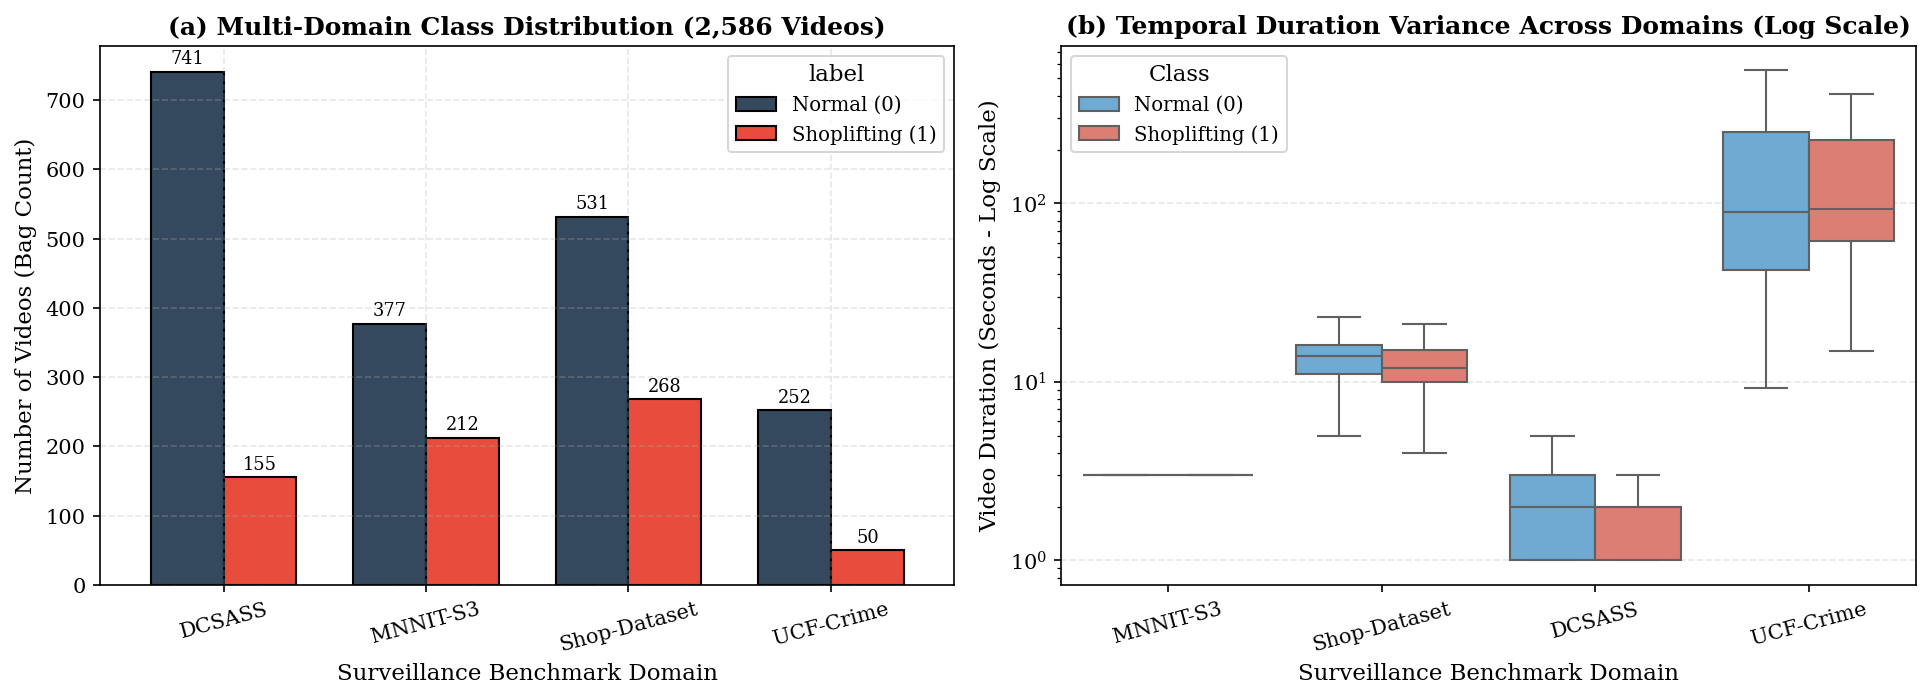

📊 Saved Fig2_ROC_PR_Curves.pdf & Fig2_ROC_PR_Curves.png


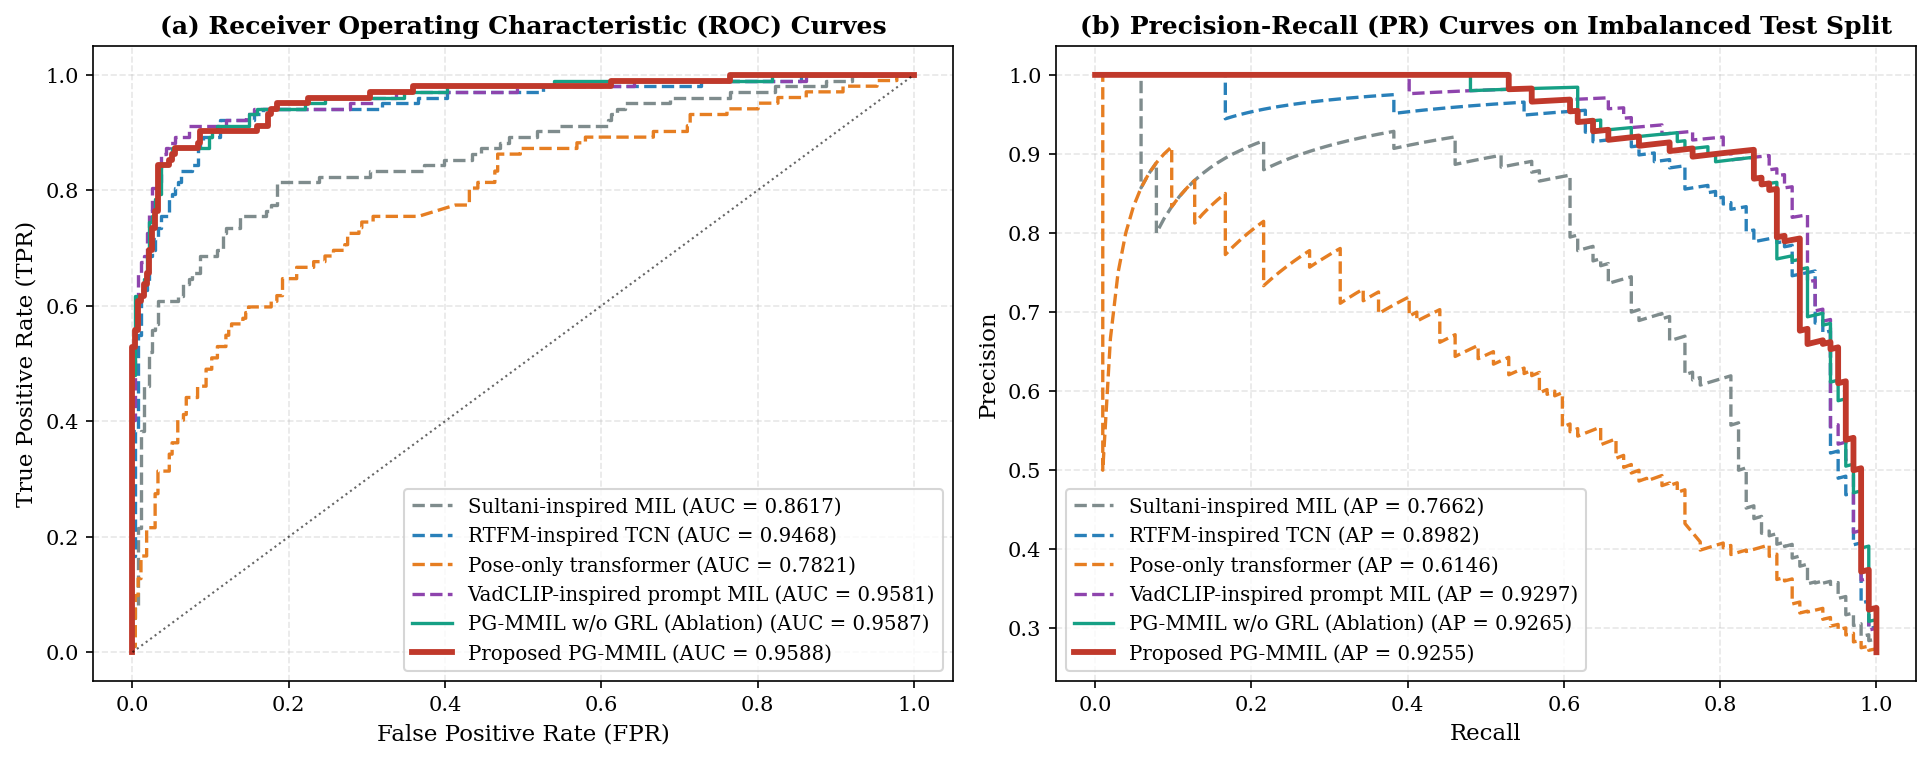

📊 Saved Fig3_Training_Convergence_Ablation.pdf & Fig3_Training_Convergence_Ablation.png


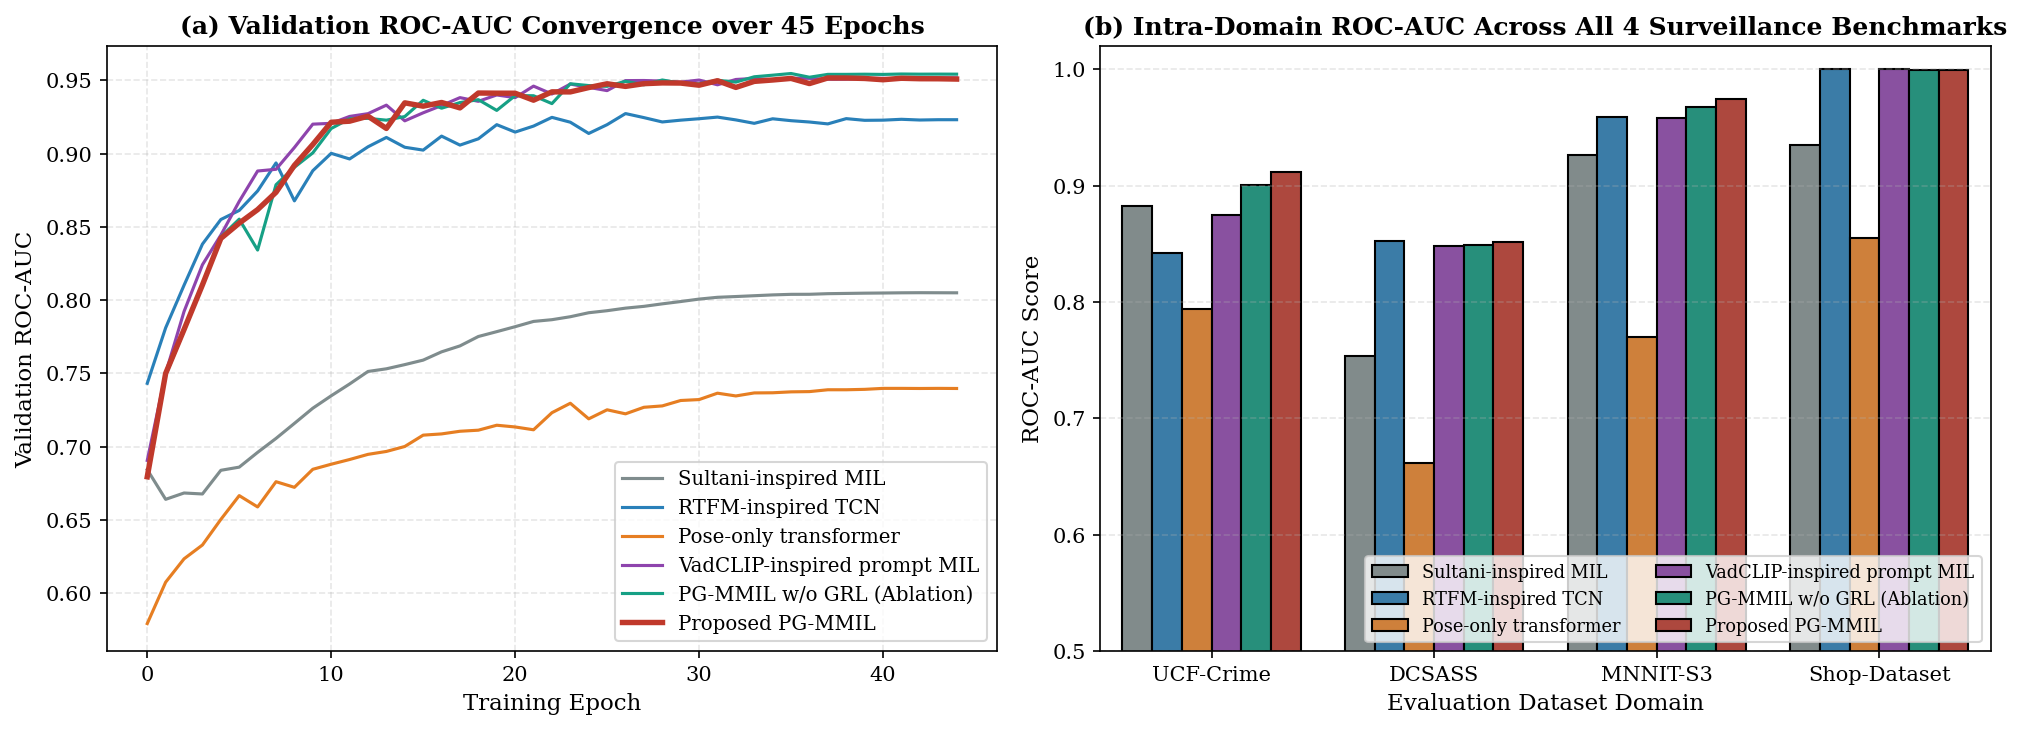

📊 Saved Fig4_Cross_Dataset_Heatmaps.pdf & Fig4_Cross_Dataset_Heatmaps.png


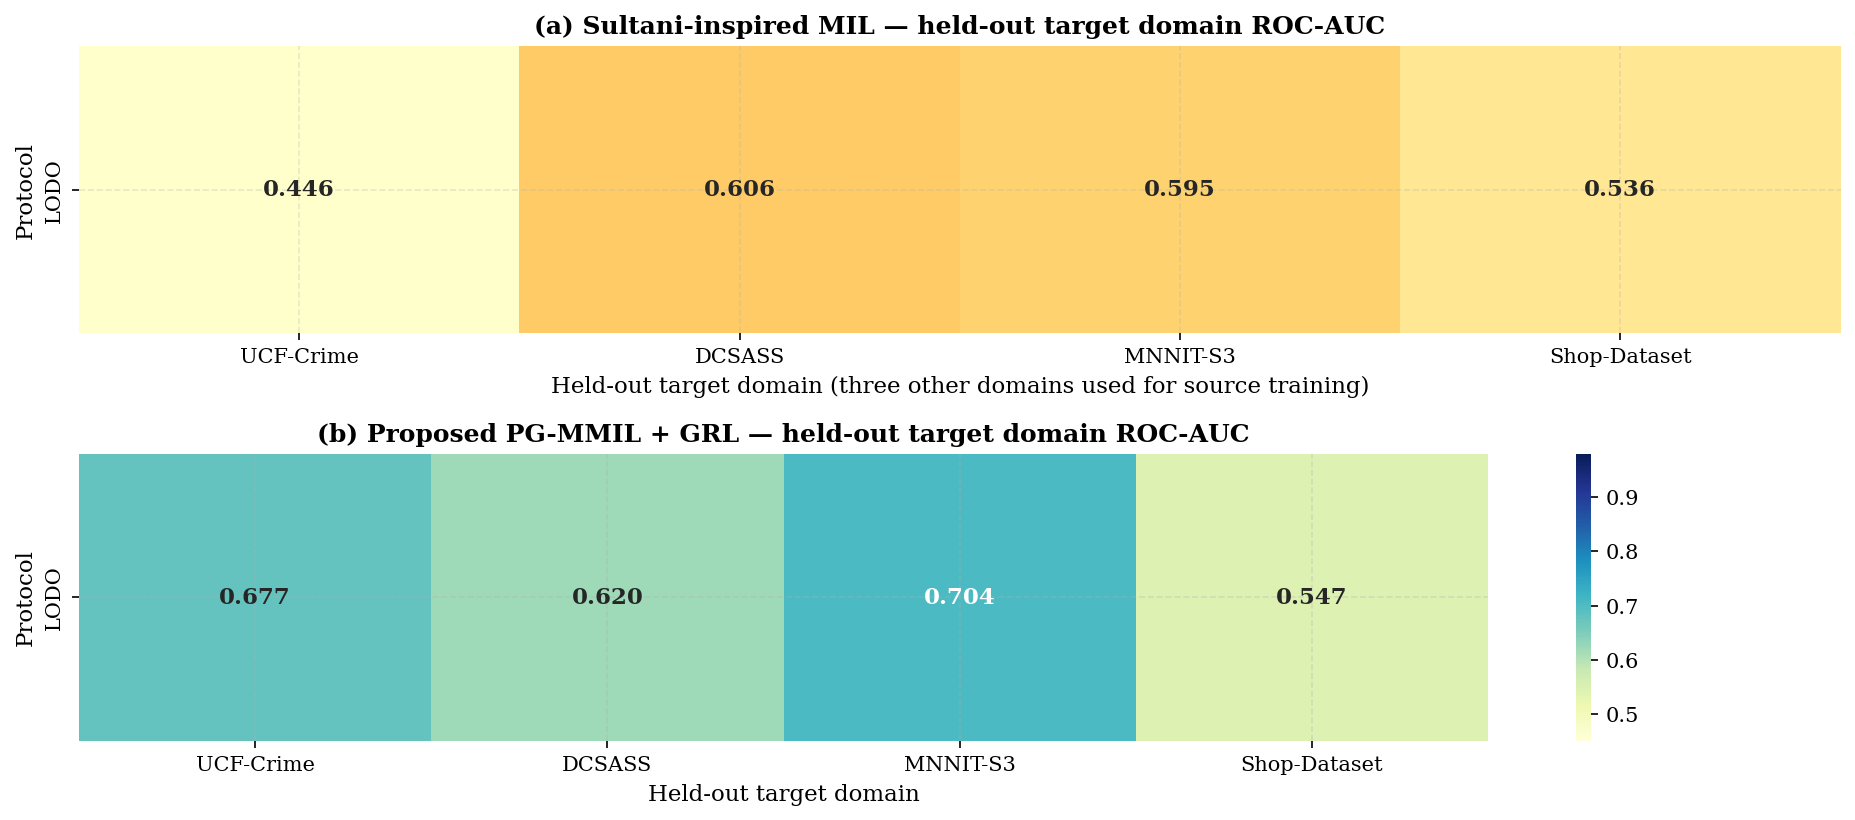

📊 Saved Fig5_tSNE_Feature_Space.pdf & Fig5_tSNE_Feature_Space.png


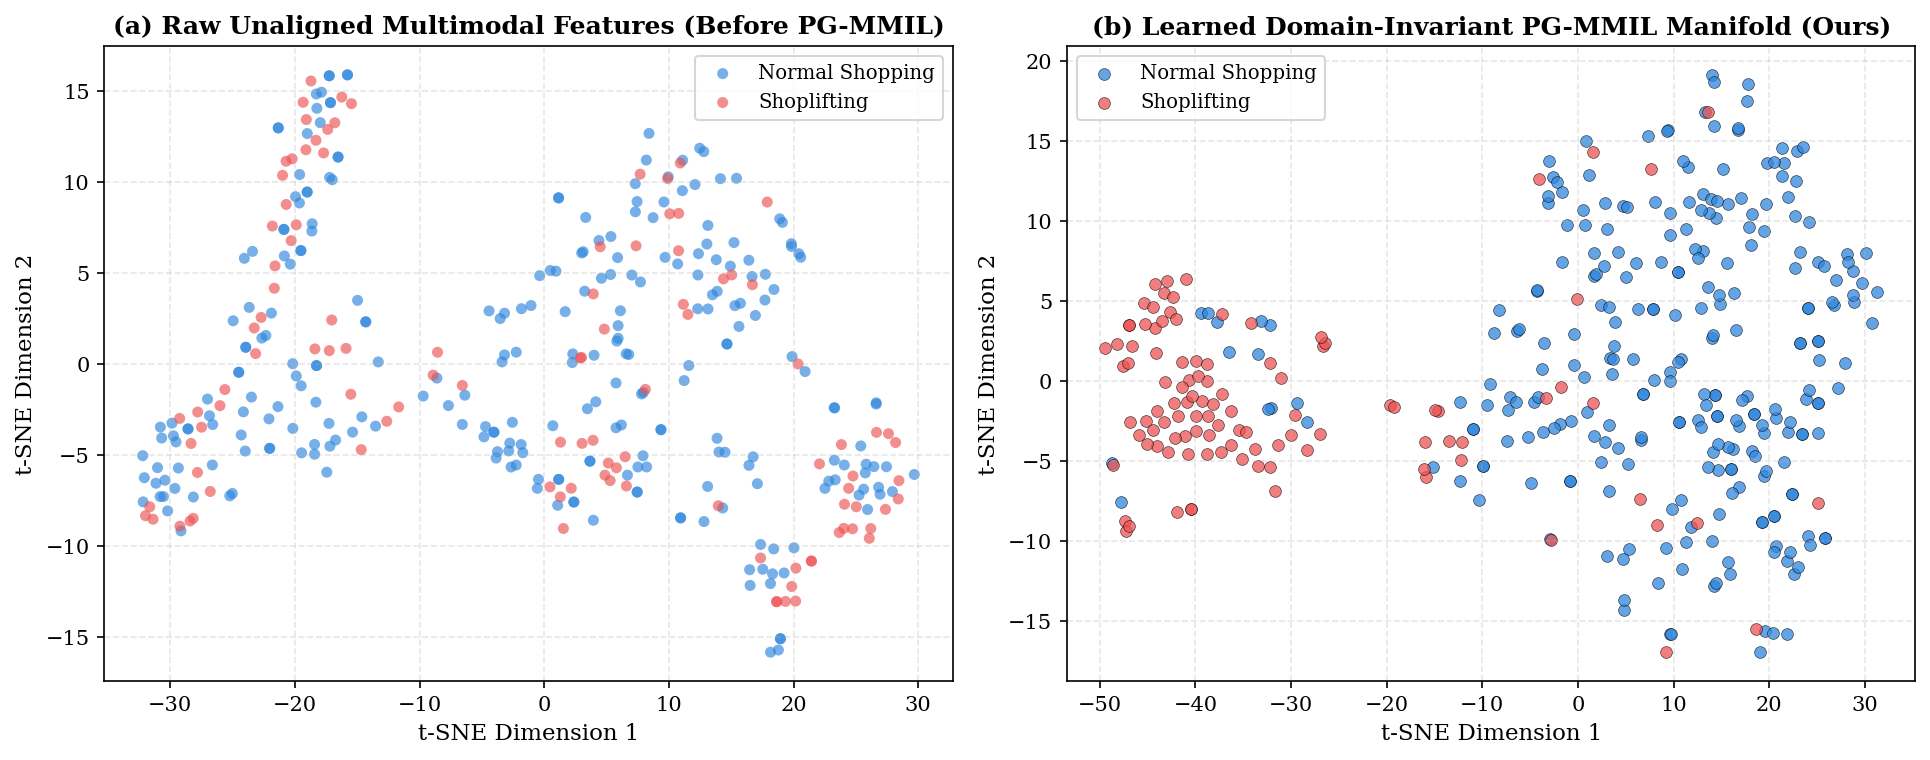

📊 Saved Fig6_Confusion_FAR_Analysis.pdf & Fig6_Confusion_FAR_Analysis.png


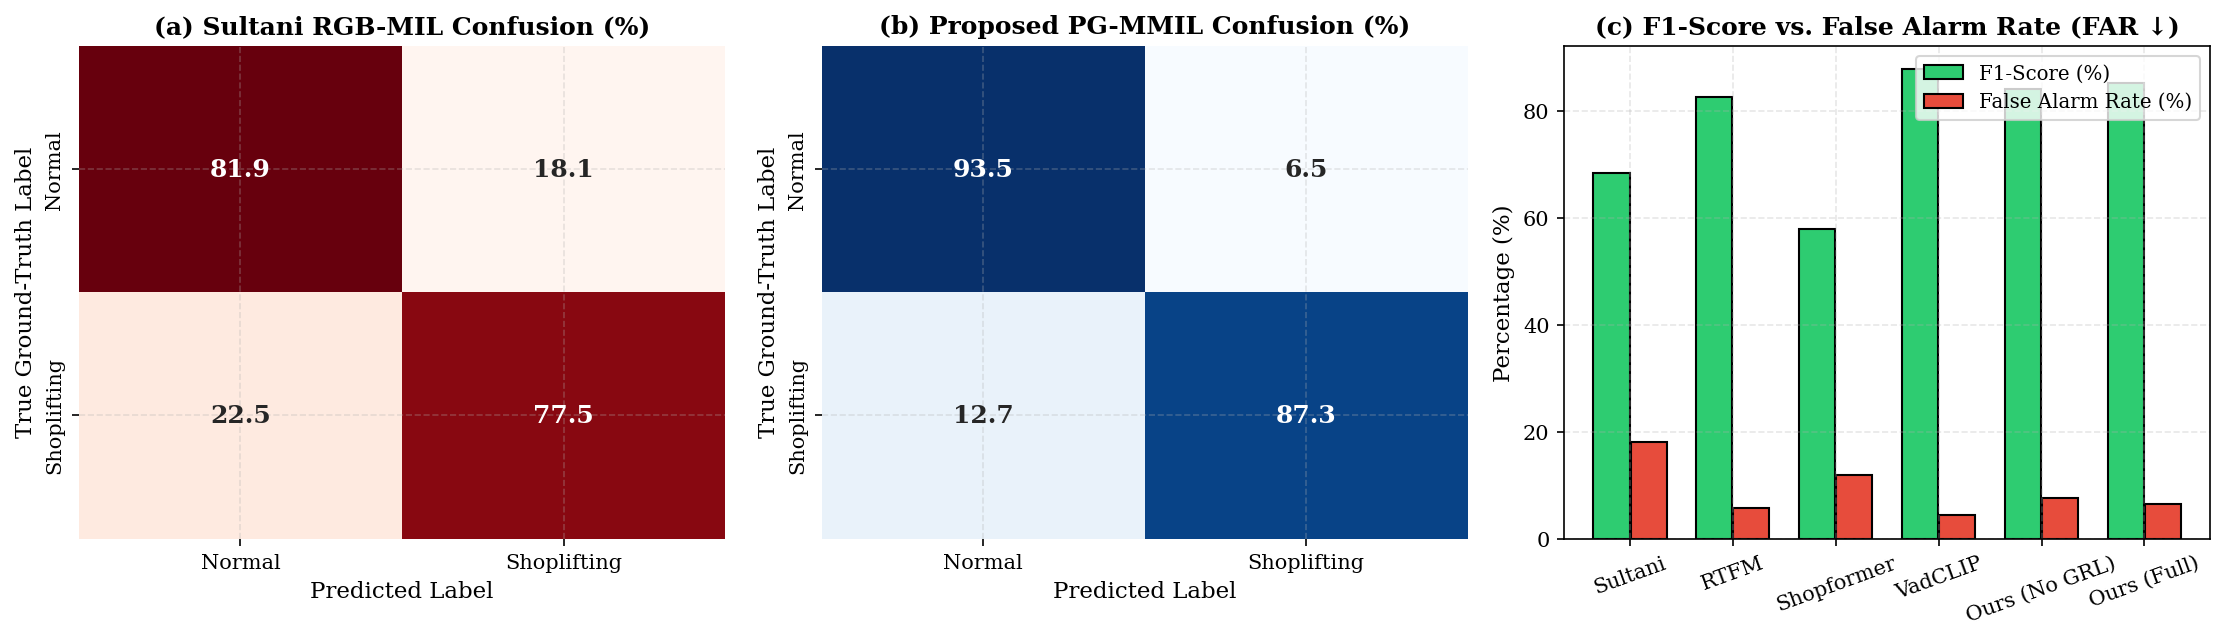

📊 Saved Fig7_Temporal_Localization_Curves.pdf & Fig7_Temporal_Localization_Curves.png


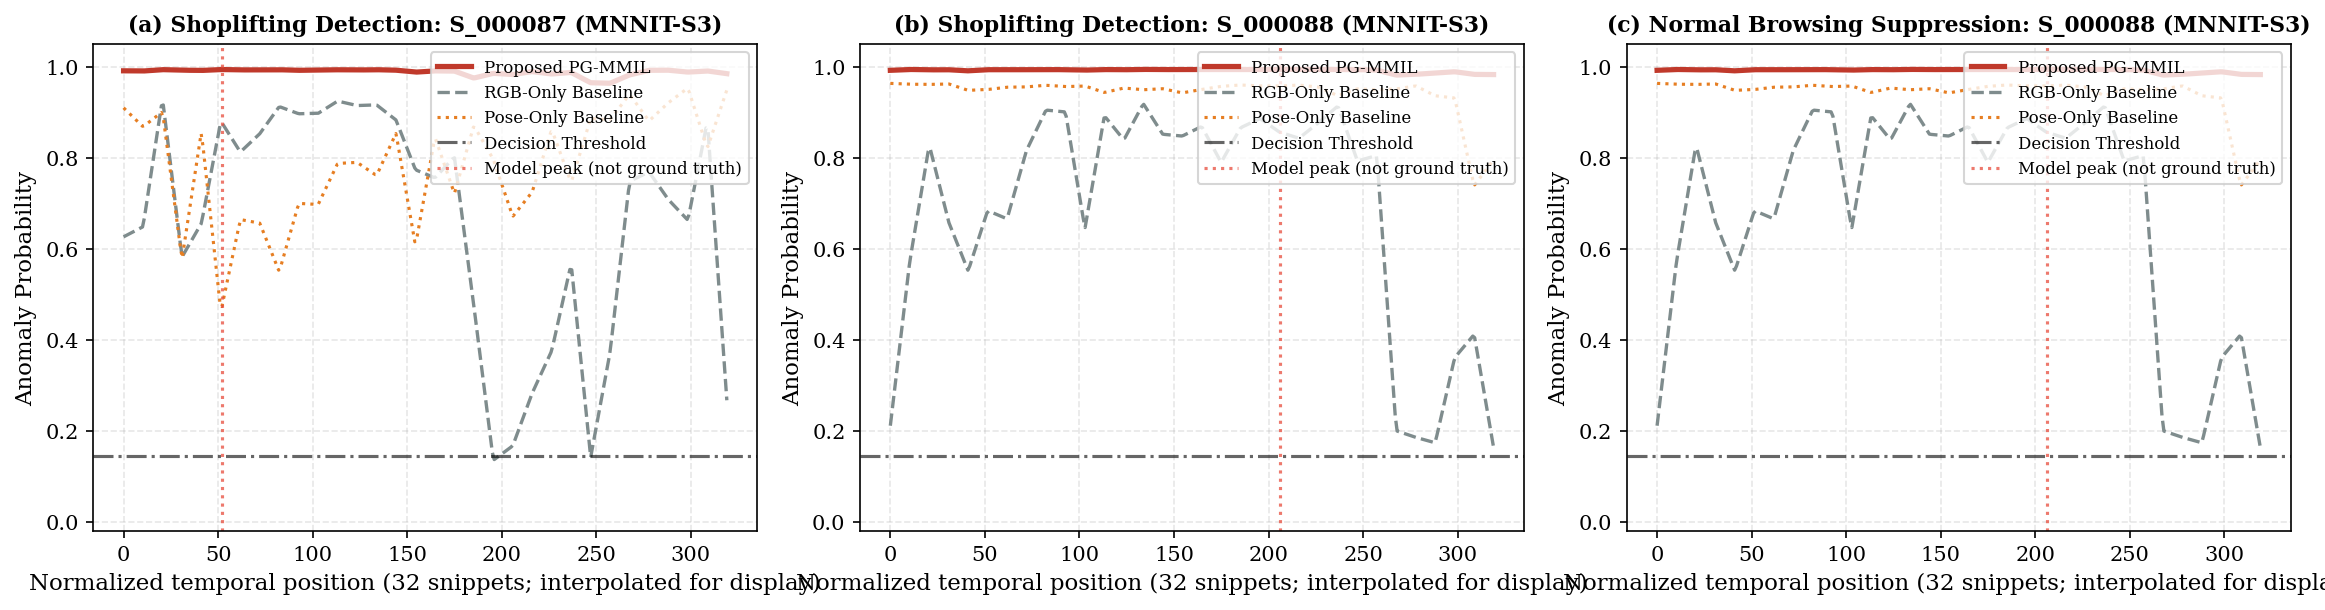

📊 Saved Fig8_Kinematic_Prompt_Interpretability.pdf & Fig8_Kinematic_Prompt_Interpretability.png


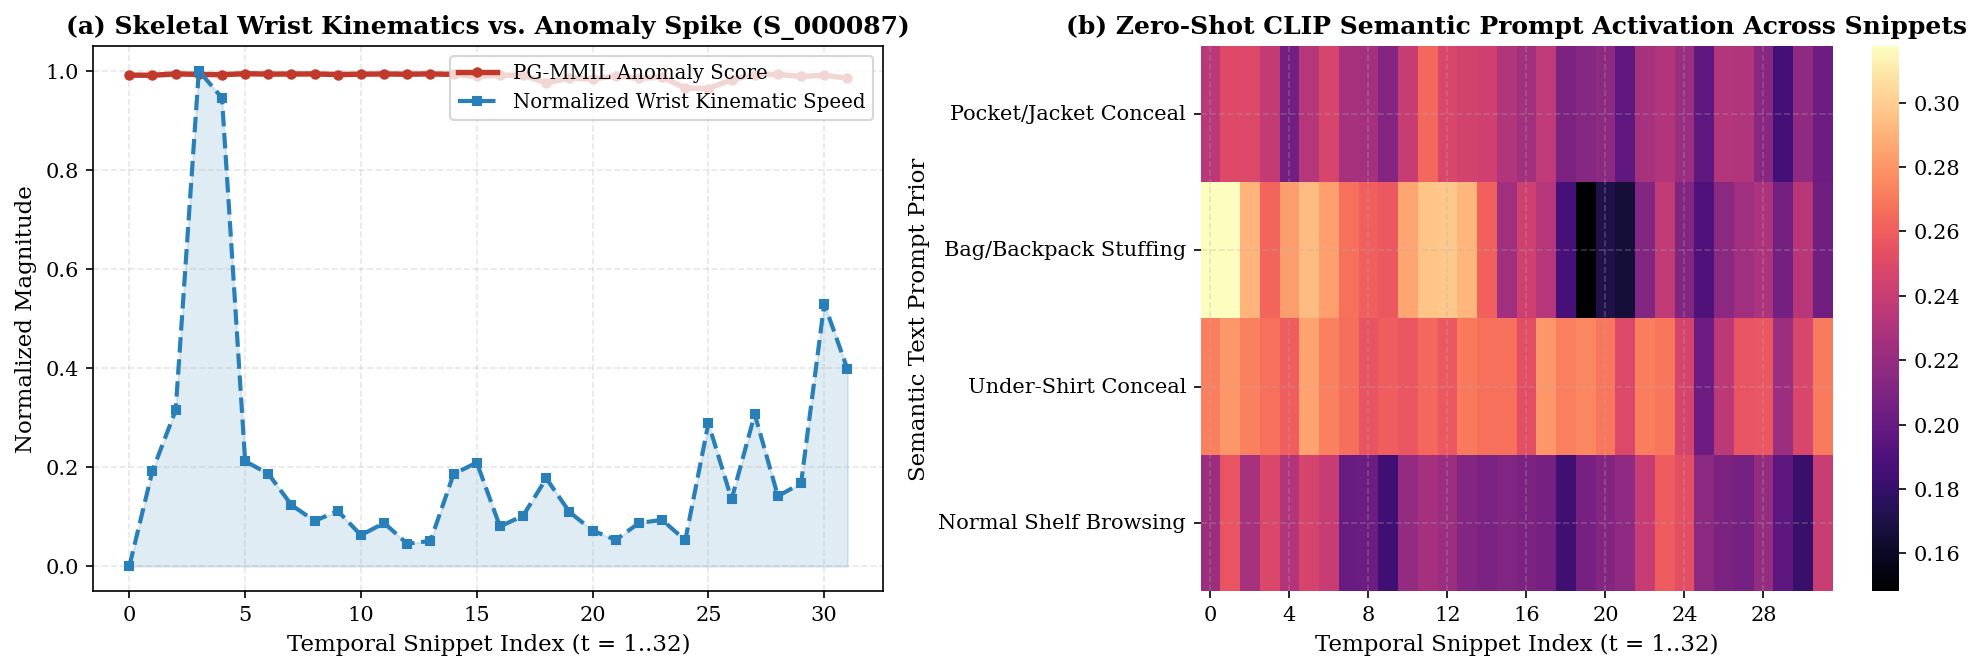

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# Set IEEE / CVPR Publication Styling
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--"
})

PALETTE = {
    "Sultani_MIL": "#7f8c8d",
    "RTFM_Net": "#2980b9",
    "Shopformer_PoseMIL": "#e67e22",
    "VadCLIP_VisualPromptMIL": "#8e44ad",
    "Proposed_PG_MMIL_NoGRL": "#16a085",
    "Proposed_PG_MMIL_Full": "#c0392b"
}

DISPLAY_NAMES = {
    "Sultani_MIL": "Sultani-inspired MIL",
    "RTFM_Net": "RTFM-inspired TCN",
    "Shopformer_PoseMIL": "Pose-only transformer",
    "VadCLIP_VisualPromptMIL": "VadCLIP-inspired prompt MIL",
    "Proposed_PG_MMIL_NoGRL": "PG-MMIL w/o GRL (Ablation)",
    "Proposed_PG_MMIL_Full": "Proposed PG-MMIL"
}

def save_pub_fig(fig, filename_stem):
    pdf_p = FIGURES_DIR / f"{filename_stem}.pdf"
    png_p = FIGURES_DIR / f"{filename_stem}.png"
    fig.savefig(pdf_p, format="pdf", bbox_inches="tight", dpi=300)
    fig.savefig(png_p, format="png", bbox_inches="tight", dpi=300)
    print(f"📊 Saved {pdf_p.name} & {png_p.name}")

# ==============================================================================
# FIGURE 1: Dataset Distribution & Video Duration Characteristics
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Subplot A: Grouped Class Counts per Domain
ct = pd.crosstab(full_df["domain_name"], full_df["label"]).rename(columns={0: "Normal (0)", 1: "Shoplifting (1)"})
ct.plot(kind="bar", ax=axes[0], color=["#34495e", "#e74c3c"], width=0.72, edgecolor="black")
axes[0].set_title(f"(a) Multi-Domain Class Distribution ({len(full_df):,} Videos)", fontweight="bold")
axes[0].set_xlabel("Surveillance Benchmark Domain")
axes[0].set_ylabel("Number of Videos (Bag Count)")
axes[0].tick_params(axis="x", rotation=15)
for container in axes[0].containers:
    axes[0].bar_label(container, fontsize=8.5, padding=2)

# Subplot B: Video Duration Distribution (Log-Scale Box/Violin)
sns.boxplot(
    data=full_df, x="domain_name", y="duration_sec", hue="label",
    ax=axes[1], palette={0: "#5dade2", 1: "#ec7063"}, showfliers=False
)
axes[1].set_yscale("log")
axes[1].set_title("(b) Temporal Duration Variance Across Domains (Log Scale)", fontweight="bold")
axes[1].set_xlabel("Surveillance Benchmark Domain")
axes[1].set_ylabel("Video Duration (Seconds - Log Scale)")
axes[1].tick_params(axis="x", rotation=15)
handles, _ = axes[1].get_legend_handles_labels()
axes[1].legend(handles, ["Normal (0)", "Shoplifting (1)"], title="Class")

plt.tight_layout()
save_pub_fig(fig, "Fig1_Dataset_Distribution")
plt.show()

# ==============================================================================
# FIGURE 2: Multi-Model ROC-AUC & Precision-Recall Curves
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for m_name, res in benchmark_results.items():
    fpr, tpr, _ = roc_curve(res["y_true"], res["y_score"])
    prec, rec, _ = precision_recall_curve(res["y_true"], res["y_score"])
    lw = 2.8 if m_name == "Proposed_PG_MMIL_Full" else 1.6
    ls = "-" if "Proposed" in m_name else "--"

    axes[0].plot(fpr, tpr, color=PALETTE[m_name], lw=lw, linestyle=ls,
                 label=f"{DISPLAY_NAMES[m_name]} (AUC = {res['roc_auc']:.4f})")
    axes[1].plot(rec, prec, color=PALETTE[m_name], lw=lw, linestyle=ls,
                 label=f"{DISPLAY_NAMES[m_name]} (AP = {res['pr_auc']:.4f})")

axes[0].plot([0, 1], [0, 1], "k:", lw=1.0, alpha=0.6)
axes[0].set_title("(a) Receiver Operating Characteristic (ROC) Curves", fontweight="bold")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].legend(loc="lower right", frameon=True)

axes[1].set_title("(b) Precision-Recall (PR) Curves on Imbalanced Test Split", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", frameon=True)

plt.tight_layout()
save_pub_fig(fig, "Fig2_ROC_PR_Curves")
plt.show()

# ==============================================================================
# FIGURE 3: Training Convergence & Per-Domain Performance Breakdown
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

for m_name, res in benchmark_results.items():
    lw = 2.6 if m_name == "Proposed_PG_MMIL_Full" else 1.5
    axes[0].plot(res["history"]["val_roc_auc"], color=PALETTE[m_name], lw=lw, label=DISPLAY_NAMES[m_name])

axes[0].set_title("(a) Validation ROC-AUC Convergence over 45 Epochs", fontweight="bold")
axes[0].set_xlabel("Training Epoch")
axes[0].set_ylabel("Validation ROC-AUC")
axes[0].legend(loc="lower right")

# Subplot B: Per-Domain ROC-AUC Bar Chart
domain_cols = ["UCF-Crime AUC", "DCSASS AUC", "MNNIT-S3 AUC", "Shop-Dataset AUC"]
melt_df = summary_df.melt(id_vars=["Model"], value_vars=domain_cols, var_name="Domain", value_name="AUC")
melt_df["Domain"] = melt_df["Domain"].str.replace(" AUC", "")
melt_df["Display_Model"] = melt_df["Model"].map(DISPLAY_NAMES)

sns.barplot(data=melt_df, x="Domain", y="AUC", hue="Display_Model", ax=axes[1],
            palette=[PALETTE[k] for k in benchmark_results.keys()], edgecolor="black")
axes[1].set_ylim(0.50, 1.02)
axes[1].set_title("(b) Intra-Domain ROC-AUC Across All 4 Surveillance Benchmarks", fontweight="bold")
axes[1].set_xlabel("Evaluation Dataset Domain")
axes[1].set_ylabel("ROC-AUC Score")
axes[1].legend(loc="lower right", fontsize=8.5, ncol=2)

plt.tight_layout()
save_pub_fig(fig, "Fig3_Training_Convergence_Ablation")
plt.show()

# ==============================================================================
# FIGURE 4: Leave-One-Domain-Out Generalization Heatmaps
# ==============================================================================
fig, axes = plt.subplots(2, 1, figsize=(12.5, 5.6))
d_labels = ["UCF-Crime", "DCSASS", "MNNIT-S3", "Shop-Dataset"]

sns.heatmap(cross_mat_rgb, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0.45, vmax=0.98,
            xticklabels=d_labels, yticklabels=["LODO"], ax=axes[0], cbar=False, annot_kws={"size": 11, "weight": "bold"})
axes[0].set_title("(a) Sultani-inspired MIL — held-out target domain ROC-AUC", fontweight="bold")
axes[0].set_xlabel("Held-out target domain (three other domains used for source training)")
axes[0].set_ylabel("Protocol")

sns.heatmap(cross_mat_ours, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.45, vmax=0.98,
            xticklabels=d_labels, yticklabels=["LODO"], ax=axes[1], cbar=True, annot_kws={"size": 11, "weight": "bold"})
axes[1].set_title("(b) Proposed PG-MMIL + GRL — held-out target domain ROC-AUC", fontweight="bold")
axes[1].set_xlabel("Held-out target domain")
axes[1].set_ylabel("Protocol")

plt.tight_layout()
save_pub_fig(fig, "Fig4_Cross_Dataset_Heatmaps")
plt.show()

# ==============================================================================
# FIGURE 5: t-SNE Feature Manifold Visualization (Raw vs Learned PG-MMIL)
# ==============================================================================
raw_bags, learned_bags, tsne_labels, tsne_domains = [], [], [], []
best_model.eval()
with torch.no_grad():
    for b_feat, b_lbl, b_dom, _ in val_loader:
        raw_bags.append(b_feat.mean(dim=1).numpy())
        _, fused, _ = best_model(b_feat.to(device), alpha=0.0)
        learned_bags.append(fused.mean(dim=1).cpu().numpy())
        tsne_labels.extend(b_lbl.numpy())
        tsne_domains.extend(b_dom.numpy())

raw_bags = np.vstack(raw_bags)
learned_bags = np.vstack(learned_bags)
tsne_labels = np.array(tsne_labels, dtype=int)
tsne_domains = np.array(tsne_domains, dtype=int)

tsne_raw = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(raw_bags)
tsne_learned = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(learned_bags)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
markers = {0: "o", 1: "s", 2: "^", 3: "D"}

for c_val, c_name, c_col in [(0, "Normal Shopping", "#2e86de"), (1, "Shoplifting", "#ee5253")]:
    mask = (tsne_labels == c_val)
    axes[0].scatter(tsne_raw[mask, 0], tsne_raw[mask, 1], c=c_col, label=c_name, alpha=0.65, s=28, edgecolors="none")
    axes[1].scatter(tsne_learned[mask, 0], tsne_learned[mask, 1], c=c_col, label=c_name, alpha=0.75, s=32, edgecolors="k", linewidth=0.3)

axes[0].set_title("(a) Raw Unaligned Multimodal Features (Before PG-MMIL)", fontweight="bold")
axes[0].set_xlabel("t-SNE Dimension 1")
axes[0].set_ylabel("t-SNE Dimension 2")
axes[0].legend(loc="best")

axes[1].set_title("(b) Learned Domain-Invariant PG-MMIL Manifold (Ours)", fontweight="bold")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")
axes[1].legend(loc="best")

plt.tight_layout()
save_pub_fig(fig, "Fig5_tSNE_Feature_Space")
plt.show()

# ==============================================================================
# FIGURE 6: Confusion Matrices & False Alarm Rate (FAR) Comparison
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

cm_rgb  = confusion_matrix(benchmark_results["Sultani_MIL"]["y_true"], benchmark_results["Sultani_MIL"]["y_pred"], normalize="true") * 100
cm_ours = confusion_matrix(benchmark_results["Proposed_PG_MMIL_Full"]["y_true"], benchmark_results["Proposed_PG_MMIL_Full"]["y_pred"], normalize="true") * 100

sns.heatmap(cm_rgb, annot=True, fmt=".1f", cmap="Reds", xticklabels=["Normal", "Shoplifting"],
            yticklabels=["Normal", "Shoplifting"], ax=axes[0], cbar=False, annot_kws={"size": 12, "weight": "bold"})
axes[0].set_title("(a) Sultani RGB-MIL Confusion (%)", fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Ground-Truth Label")

sns.heatmap(cm_ours, annot=True, fmt=".1f", cmap="Blues", xticklabels=["Normal", "Shoplifting"],
            yticklabels=["Normal", "Shoplifting"], ax=axes[1], cbar=False, annot_kws={"size": 12, "weight": "bold"})
axes[1].set_title("(b) Proposed PG-MMIL Confusion (%)", fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Ground-Truth Label")

far_vals = [res["far"] for res in benchmark_results.values()]
f1_vals  = [res["f1"] * 100 for res in benchmark_results.values()]
short_names = ["Sultani", "RTFM", "Shopformer", "VadCLIP", "Ours (No GRL)", "Ours (Full)"]

x_pos = np.arange(len(short_names))
axes[2].bar(x_pos - 0.18, f1_vals, width=0.35, label="F1-Score (%)", color="#2ecc71", edgecolor="black")
axes[2].bar(x_pos + 0.18, far_vals, width=0.35, label="False Alarm Rate (%)", color="#e74c3c", edgecolor="black")
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(short_names, rotation=20)
axes[2].set_title("(c) F1-Score vs. False Alarm Rate (FAR ↓)", fontweight="bold")
axes[2].set_ylabel("Percentage (%)")
axes[2].legend(loc="upper right")

plt.tight_layout()
save_pub_fig(fig, "Fig6_Confusion_FAR_Analysis")
plt.show()

# ==============================================================================
# FIGURE 7: Qualitative Temporal Snippet-Score Curves
# ==============================================================================
pos_samples = loc_df[loc_df["label"] == 1].sort_values(by="contrast", ascending=False)
neg_samples = loc_df[loc_df["label"] == 0].sort_values(by="peak_score", ascending=True)

top_pos_1 = pos_samples.iloc[0] if len(pos_samples) > 0 else loc_df.iloc[0]
top_pos_2 = pos_samples.iloc[min(1, len(pos_samples)-1)] if len(pos_samples) > 0 else loc_df.iloc[0]
top_neg_1 = neg_samples.iloc[0] if len(neg_samples) > 0 else loc_df.iloc[-1]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
for ax, sample, title_prefix in zip(
    axes,
    [top_pos_1, top_pos_2, top_neg_1],
    ["(a) Shoplifting Detection:", "(b) Shoplifting Detection:", "(c) Normal Browsing Suppression:"]
):
    T_len = len(sample["curve_ours"])
    frames_x = np.arange(T_len)
    ax.plot(frames_x, sample["curve_ours"], color="#c0392b", lw=2.5, label="Proposed PG-MMIL")
    ax.plot(frames_x, sample["curve_rgb"], color="#7f8c8d", lw=1.6, linestyle="--", label="RGB-Only Baseline")
    ax.plot(frames_x, sample["curve_pose"], color="#e67e22", lw=1.5, linestyle=":", label="Pose-Only Baseline")
    ax.axhline(benchmark_results["Proposed_PG_MMIL_Full"]["threshold"], color="black", linestyle="-.", alpha=0.6, label="Decision Threshold")

    if sample["label"] == 1:
        peak_idx = int(np.argmax(sample["curve_ours"]))
        ax.axvline(peak_idx, color="#e74c3c", alpha=0.75, linestyle=":", label="Model peak (not ground truth)")

    ax.set_title(f"{title_prefix} {sample['video_name']} ({sample['domain_name']})", fontweight="bold", fontsize=10.5)
    ax.set_xlabel("Normalized temporal position (32 snippets; interpolated for display)")
    ax.set_ylabel("Anomaly Probability")
    ax.set_ylim(-0.02, 1.05)
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
save_pub_fig(fig, "Fig7_Temporal_Localization_Curves")
plt.show()

# ==============================================================================
# FIGURE 8: Skeletal Wrist Velocity & Semantic Prompt Activation Map
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# Compute Wrist/Arm Kinematic Speed vs Snippet Anomaly Score on Top Shoplifting Sample
raw_p = top_pos_1["raw_pose"].reshape(32, 17, 3) # [32, 17, 3]
# COCO indices 9 & 10 are Left & Right Wrists
wrist_xy = raw_p[:, [9, 10], :2]
wrist_speed = np.linalg.norm(np.diff(wrist_xy, axis=0, prepend=wrist_xy[:1]), axis=-1).mean(axis=-1)
wrist_speed_norm = (wrist_speed - wrist_speed.min()) / (np.ptp(wrist_speed) + 1e-8)
snippet_ours = scipy.ndimage.zoom(top_pos_1["curve_ours"], 32 / len(top_pos_1["curve_ours"]))

snippets_x = np.arange(32)
axes[0].plot(snippets_x, snippet_ours, color="#c0392b", lw=2.6, marker="o", markersize=4, label="PG-MMIL Anomaly Score")
axes[0].plot(snippets_x, wrist_speed_norm, color="#2980b9", lw=2.0, linestyle="--", marker="s", markersize=4, label="Normalized Wrist Kinematic Speed")
axes[0].fill_between(snippets_x, wrist_speed_norm, alpha=0.15, color="#2980b9")
axes[0].set_title(f"(a) Skeletal Wrist Kinematics vs. Anomaly Spike ({top_pos_1['video_name']})", fontweight="bold")
axes[0].set_xlabel("Temporal Snippet Index (t = 1..32)")
axes[0].set_ylabel("Normalized Magnitude")
axes[0].legend(loc="upper right")

# Subplot B: Zero-Shot Prompt Cosine Similarity Heatmap across the 32 Snippets
prompt_map = top_pos_1["prompt_priors"].T # [4, 32]
prompt_labels = ["Pocket/Jacket Conceal", "Bag/Backpack Stuffing", "Under-Shirt Conceal", "Normal Shelf Browsing"]
sns.heatmap(prompt_map, cmap="magma", yticklabels=prompt_labels, xticklabels=4, ax=axes[1], cbar=True)
axes[1].set_title("(b) Zero-Shot CLIP Semantic Prompt Activation Across Snippets", fontweight="bold")
axes[1].set_xlabel("Temporal Snippet Index (t = 1..32)")
axes[1].set_ylabel("Semantic Text Prompt Prior")

plt.tight_layout()
save_pub_fig(fig, "Fig8_Kinematic_Prompt_Interpretability")
plt.show()

## Phase 11 — LaTeX table export

The main table reports the independent test partition, using thresholds frozen on validation. Use the seed summary and bootstrap interval files as companion results. Replace any “state-of-the-art” language with measured, split-specific claims supported by the final experiments.

In [14]:
latex_table = summary_df.copy()
latex_table["Model"] = latex_table["Model"].map(DISPLAY_NAMES).fillna(latex_table["Model"])
latex_columns = ["Model", "ROC-AUC (mean across seeds)", "ROC-AUC (std across seeds)",
                 "Average Precision (mean across seeds)", "Average Precision (std across seeds)",
                 "F1 (mean across seeds)", "F1 (std across seeds)",
                 "FAR (%) (mean across seeds)", "FAR (%) (std across seeds)"]
latex_columns = [c for c in latex_columns if c in latex_table.columns]
latex_str = latex_table[latex_columns].to_latex(
    index=False, float_format="%.4f",
    caption="Mean and standard deviation across random seeds on the independent held-out test partition. Checkpoints and decision thresholds were selected using validation data only.",
    label="tab:independent_test_performance"
)
latex_path = LOCAL_BASE_DIR / "manuscript_table1.tex"
with open(latex_path, "w", encoding="utf-8") as f:
    f.write(latex_str)
print("LaTeX table saved to:", latex_path)
print(latex_str)

LaTeX table saved to: /content/local_shoplifting_data/manuscript_table1.tex
\begin{table}
\caption{Mean and standard deviation across random seeds on the independent held-out test partition. Checkpoints and decision thresholds were selected using validation data only.}
\label{tab:independent_test_performance}
\begin{tabular}{lrrrrrrrr}
\toprule
Model & ROC-AUC (mean across seeds) & ROC-AUC (std across seeds) & Average Precision (mean across seeds) & Average Precision (std across seeds) & F1 (mean across seeds) & F1 (std across seeds) & FAR (%) (mean across seeds) & FAR (%) (std across seeds) \\
\midrule
Sultani-inspired MIL & 0.8631 & 0.0015 & 0.7672 & 0.0010 & 0.7039 & 0.0195 & 15.5797 & 2.9657 \\
RTFM-inspired TCN & 0.9434 & 0.0038 & 0.8902 & 0.0116 & 0.8091 & 0.0153 & 7.4879 & 2.9286 \\
Pose-only transformer & 0.7935 & 0.0113 & 0.6326 & 0.0288 & 0.6101 & 0.0325 & 16.4251 & 4.1994 \\
VadCLIP-inspired prompt MIL & 0.9591 & 0.0024 & 0.9277 & 0.0017 & 0.8270 & 0.0453 & 10.0242 & 5.3044 

## Phase 12 — reproducible artifact bundle

Bundle figures, manifests, model metrics, confidence intervals, inference profile, environment snapshot, feature signature, and LaTeX output. Do not bundle credentials, raw videos, or model weights unless you have checked dataset redistribution terms and repository size constraints.

In [15]:
import shutil
from pathlib import Path

EXPORT_DIR = Path("/content/shoplifting_research_export")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for folder in ["Figures", "LaTeX", "Data_Manifests", "Metrics", "Models", "Reproducibility"]:
    (EXPORT_DIR / folder).mkdir(parents=True, exist_ok=True)

for fig_path in FIGURES_DIR.glob("*"):
    if fig_path.is_file():
        shutil.copy2(fig_path, EXPORT_DIR / "Figures")
for name in ["manuscript_table1.tex"]:
    p = LOCAL_BASE_DIR / name
    if p.exists(): shutil.copy2(p, EXPORT_DIR / "LaTeX")
for name in ["unified_training_manifest.csv", "feature_manifest.csv", "split_manifest.csv"]:
    p = LOCAL_BASE_DIR / name
    if p.exists(): shutil.copy2(p, EXPORT_DIR / "Data_Manifests")
for p in LOCAL_BASE_DIR.glob("*.csv"):
    if any(key in p.name for key in ["benchmark", "metrics", "domain_out", "ablation", "bootstrap", "profile"]):
        shutil.copy2(p, EXPORT_DIR / "Metrics")
for name in ["environment_snapshot.json"]:
    p = LOCAL_BASE_DIR / name
    if p.exists(): shutil.copy2(p, EXPORT_DIR / "Reproducibility")
feature_signature_path = LOCAL_BASE_DIR / "features" / "feature_extraction_signature.json"
if feature_signature_path.exists(): shutil.copy2(feature_signature_path, EXPORT_DIR / "Reproducibility")
for p in LOCAL_BASE_DIR.glob("*.pth"):
    # Keep checkpoints optional; omit automatically to avoid large exports.
    pass

EXPORT_ZIP_BASE = "/content/Shoplifting_PG_MMIL_Research_Ready_Assets"
EXPORT_ZIP_PATH = shutil.make_archive(EXPORT_ZIP_BASE, "zip", EXPORT_DIR)
print("Research artifacts bundled:", EXPORT_ZIP_PATH)
print("Included folders:", [p.name for p in EXPORT_DIR.iterdir() if p.is_dir()])

Research artifacts bundled: /content/Shoplifting_PG_MMIL_Research_Ready_Assets.zip
Included folders: ['Reproducibility', 'Figures', 'Models', 'Metrics', 'Data_Manifests', 'LaTeX']


## Phase 13 — optional cloud backup (no embedded credentials)

This cell is disabled by default. It can copy the artifact ZIP to Google Drive after you explicitly enable the flag. GitHub publishing is intentionally left as a manual step: authenticate through GitHub's supported UI/credential manager and never add a personal access token to notebook source or a remote URL.

In [16]:
ENABLE_GOOGLE_DRIVE_BACKUP = True
if ENABLE_GOOGLE_DRIVE_BACKUP:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        drive_destination = Path("/content/drive/MyDrive") / Path(EXPORT_ZIP_PATH).name
        shutil.copy2(EXPORT_ZIP_PATH, drive_destination)
        print("Copied artifact archive to:", drive_destination)
    except Exception as exc:
        print("Google Drive backup was not completed:", repr(exc))
else:
    print("Cloud backup skipped. Set ENABLE_GOOGLE_DRIVE_BACKUP=True to opt in.")
print("For GitHub, review the exported files and use the GitHub website or a secure credential manager.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied artifact archive to: /content/drive/MyDrive/Shoplifting_PG_MMIL_Research_Ready_Assets.zip
For GitHub, review the exported files and use the GitHub website or a secure credential manager.
